# Propensión de compra de bicicletas según el perfil del cliente

**Machine Learning for Business · Proyecto 1 · Dataset 2: *Sales Data***

Este cuaderno desarrolla el ciclo completo de CRISP-DM [Chapman et al., 2000]: comprensión del negocio, comprensión y preparación de los datos, modelado, evaluación y recomendaciones. Todas las cifras que aparecen en el texto provienen de celdas ejecutadas; el cuaderno es reproducible de principio a fin con `data/01_raw/sales_data.csv` y las semillas fijadas. El mismo flujo (limpieza, partición por grupos, ajuste con Optuna y evaluación) está implementado como proyecto Kedro reproducible en `src/` (`kedro run`).

**Contenido**

1. Comprensión del negocio
2. Configuración
3. Comprensión y preparación de los datos
4. Exploración: ¿quién compra bicicletas?
5. Diseño experimental
6. Modelado: línea base, candidatos y ajuste de hiperparámetros
7. Evaluación final en datos no vistos
8. Interpretación del modelo
9. Valor de negocio y recomendaciones por edad, género y mercado
10. Limitaciones, sesgos y riesgos
11. Conclusiones
12. Referencias

## 1. Comprensión del negocio

| Elemento | Descripción |
|---|---|
| **Contexto** | Empresa que comercializa bicicletas, accesorios y ropa de ciclismo en seis mercados (Estados Unidos, Canadá, Reino Unido, Alemania, Francia y Australia). Las bicicletas son un producto de ticket alto y concentran la mayor parte de la ganancia. |
| **Stakeholder** | Gerencia de Marketing y Ventas Regionales, que debe decidir a qué perfiles de cliente, mercados y momentos del año dirigir los esfuerzos comerciales con un presupuesto limitado. |
| **Pregunta de negocio** | *Conociendo únicamente el perfil del cliente (edad, género, país y estado) y el mes del pedido, ¿qué probabilidad existe de que el pedido corresponda a una bicicleta y, por tanto, a qué perfiles conviene dirigir las ventas de cada línea de producto?* |
| **Objetivo analítico** | Clasificación binaria con salida probabilística: `es_bicicleta = 1` si la categoría del pedido es *Bikes*. La probabilidad permite **ordenar** perfiles por propensión, no solo etiquetarlos. |
| **Variables permitidas** | Edad, género, país, estado y mes: lo que se conoce *antes* de saber qué se compra. |
| **Variables excluidas** | Producto, subcategoría, precio, costo, cantidad, ingreso y ganancia. Determinan la categoría comprada o son consecuencia de ella: usarlas sería **fuga de información** [Kaufman et al., 2012]. La ganancia se utiliza únicamente para valorar el resultado, nunca como predictor. |
| **Métricas de éxito (técnicas)** | PR-AUC (principal, porque la clase positiva es minoritaria [Saito & Rehmsmeier, 2015]), ROC-AUC y *log-loss*, evaluadas en datos no vistos y comparadas contra una línea base. |
| **Métricas de éxito (comerciales)** | *Lift* por decil y porcentaje de compras de bicicleta y de ganancia capturado al contactar al *top-k %* de los perfiles mejor puntuados, frente a contactar al azar [Provost & Fawcett, 2013]. |
| **Impacto esperado** | Concentrar la inversión comercial en los perfiles con mayor propensión y orientar a los de menor propensión hacia accesorios y ropa, mejorando la eficiencia del contacto sin ampliar el presupuesto. |

## 2. Configuración

In [1]:
import json
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import lightgbm as lgb
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import shap
import xgboost as xgb
from catboost import CatBoostClassifier
from IPython.display import Markdown, display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    log_loss,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, SplineTransformer

optuna.logging.set_verbosity(optuna.logging.WARNING)

SEED = 42
# El cuaderno se puede ejecutar desde la raíz del repositorio o desde la carpeta notebooks/.
DATA_PATH = next(p for p in ("data/01_raw/sales_data.csv", "../data/01_raw/sales_data.csv") if Path(p).exists())

# Paleta sobria y consistente: un color de énfasis, un color de contraste y neutros.
AZUL, NARANJA, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#898781"
TINTA, TINTA_2, REJILLA, FONDO = "#0b0b0b", "#52514e", "#e1e0d9", "#fcfcfb"
AZULES = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
CMAP_SEC = mpl.colors.LinearSegmentedColormap.from_list("secuencial", AZULES)

mpl.rcParams.update(
    {
        "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
        "axes.edgecolor": REJILLA, "axes.labelcolor": TINTA_2, "axes.titlecolor": TINTA,
        "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8,
        "xtick.color": TINTA_2, "ytick.color": TINTA_2, "text.color": TINTA,
        "font.family": "DejaVu Sans", "font.size": 10, "legend.frameon": False,
        "figure.dpi": 110, "savefig.dpi": 150, "axes.axisbelow": True,
    }
)
pd.options.display.float_format = "{:,.4f}".format
pd.options.display.max_columns = 50

## 3. Comprensión y preparación de los datos

Cada fila del dataset es una **línea de pedido** con su fecha, el perfil del cliente (edad, género, país y estado), el producto y sus magnitudes económicas. No existe un identificador de cliente: el análisis es a nivel de pedido, no de cliente.

### 3.1 Calidad de los datos

In [2]:
raw = pd.read_csv(DATA_PATH, parse_dates=["Date"])
print(f"Filas: {len(raw):,} | Columnas: {raw.shape[1]}")
print(f"Rango de fechas: {raw['Date'].min():%Y-%m-%d} a {raw['Date'].max():%Y-%m-%d}")
display(raw.head(3))

calidad = pd.DataFrame(
    {
        "tipo": raw.dtypes.astype(str),
        "faltantes": raw.isna().sum(),
        "valores_distintos": raw.nunique(),
    }
)
display(calidad)

Filas: 113,036 | Columnas: 18
Rango de fechas: 2011-01-01 a 2016-07-31


,Date,Day,Month,Year,Customer_Age,Age_Group,Customer_Gender,Country,State,Product_Category,Sub_Category,Product,Order_Quantity,Unit_Cost,Unit_Price,Profit,Cost,Revenue
0,2013-11-26,26,November,2013,19,Youth (<25),M,Canada,British Columbia,Accessories,Bike Racks,Hitch Rack - 4-Bike,8,45,120,590,360,950
1,2015-11-26,26,November,2015,19,Youth (<25),M,Canada,British Columbia,Accessories,Bike Racks,Hitch Rack - 4-Bike,8,45,120,590,360,950
2,2014-03-23,23,March,2014,49,Adults (35-64),M,Australia,New South Wales,Accessories,Bike Racks,Hitch Rack - 4-Bike,23,45,120,1366,1035,2401


,tipo,faltantes,valores_distintos
Date,datetime64[us],0,1884
Day,int64,0,31
Month,str,0,12
Year,int64,0,6
Customer_Age,int64,0,70
Age_Group,str,0,4
Customer_Gender,str,0,2
Country,str,0,6
State,str,0,53
Product_Category,str,0,3


In [3]:
n_dup = int(raw.duplicated().sum())
print(f"Filas duplicadas exactas (18 columnas idénticas): {n_dup:,} ({n_dup / len(raw):.2%})")

# Consistencia aritmética y de calendario entre columnas.
costo_ok = (raw["Cost"] == raw["Unit_Cost"] * raw["Order_Quantity"]).mean()
ganancia_ok = (raw["Profit"] == raw["Revenue"] - raw["Cost"]).mean()
fecha_ok = (
    (raw["Date"].dt.day == raw["Day"])
    & (raw["Date"].dt.year == raw["Year"])
    & (raw["Date"].dt.month_name() == raw["Month"])
).mean()
print(f"Cost = Unit_Cost × Order_Quantity en el {costo_ok:.2%} de las filas")
print(f"Profit = Revenue − Cost en el {ganancia_ok:.2%} de las filas")
print(f"Date coherente con Day/Month/Year en el {fecha_ok:.2%} de las filas")

# Etiquetas de catálogo: cada producto debería pertenecer a una sola categoría y subcategoría.
sin_dup = raw.drop_duplicates()
cat_por_producto = sin_dup.groupby("Product")["Product_Category"].nunique()
sub_por_producto = sin_dup.groupby("Product")["Sub_Category"].nunique()
print(f"Productos con más de una categoría: {(cat_por_producto > 1).sum()} | "
      f"con más de una subcategoría: {(sub_por_producto > 1).sum()}")

# Valores atípicos en la edad (regla del rango intercuartílico) y ganancia negativa.
q1, q3 = sin_dup["Customer_Age"].quantile([0.25, 0.75])
lim_sup = q3 + 1.5 * (q3 - q1)
print(f"Edad: mediana {sin_dup['Customer_Age'].median():.0f}, rango {sin_dup['Customer_Age'].min()}–"
      f"{sin_dup['Customer_Age'].max()}, {(sin_dup['Customer_Age'] > lim_sup).sum():,} filas sobre {lim_sup:.0f} años (IQR)")
print(f"Pedidos con ganancia negativa: {(sin_dup['Profit'] < 0).sum()}")

Filas duplicadas exactas (18 columnas idénticas): 1,000 (0.88%)


Cost = Unit_Cost × Order_Quantity en el 100.00% de las filas
Profit = Revenue − Cost en el 100.00% de las filas
Date coherente con Day/Month/Year en el 100.00% de las filas


Productos con más de una categoría: 4 | con más de una subcategoría: 8
Edad: mediana 35, rango 17–87, 526 filas sobre 66 años (IQR)
Pedidos con ganancia negativa: 58


**Decisiones de limpieza**

- **Faltantes:** no hay ninguno, por lo que no se imputa nada.
- **Duplicados:** las filas idénticas en las 18 columnas se eliminan; no aportan información y distorsionarían la evaluación.
- **Consistencia:** costo, ganancia y fechas son coherentes en el 100 % de las filas; no hay errores de captura que corregir.
- **Etiquetas de catálogo:** unos pocos productos aparecen con más de una categoría o subcategoría, aunque cada producto tiene un único precio y costo. Se asigna a cada producto la etiqueta mayoritaria, lo que evita ruido en la variable objetivo.
- **Atípicos:** las edades extremas son plausibles y la ganancia alta corresponde a bicicletas de precio elevado; son ventas reales. Se conservan, y los modelos basados en árboles son robustos a ellas.

In [4]:
df = raw.drop_duplicates().copy()
modal = df.groupby("Product")[["Product_Category", "Sub_Category"]].agg(lambda s: s.value_counts().index[0])
corr_cat = int((df["Product_Category"] != df["Product"].map(modal["Product_Category"])).sum())
df["Product_Category"] = df["Product"].map(modal["Product_Category"])
df["Sub_Category"] = df["Product"].map(modal["Sub_Category"])
df = df.reset_index(drop=True)
print(f"Filas tras eliminar duplicados: {len(df):,} | etiquetas de categoría corregidas: {corr_cat}")

Filas tras eliminar duplicados: 112,036 | etiquetas de categoría corregidas: 10


### 3.2 Estructura temporal: el catálogo cambia durante el periodo

Antes de definir la población de análisis conviene observar cómo evoluciona la mezcla de productos en el tiempo.

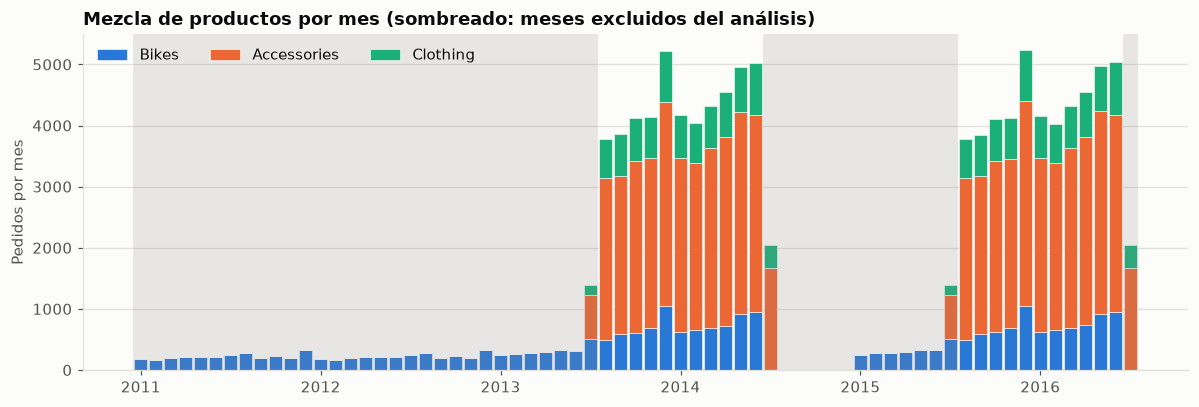

Meses calendario con datos: 62 | meses de catálogo estable: 22


In [5]:
df["mes_calendario"] = df["Date"].dt.to_period("M")
mensual = df.pivot_table(index="mes_calendario", columns="Product_Category", values="Date", aggfunc="count").fillna(0)
mensual = mensual.reindex(pd.period_range(mensual.index.min(), mensual.index.max(), freq="M"), fill_value=0)

completo = (mensual > 0).all(axis=1)          # el mes contiene las tres categorías
estable = completo & completo.shift(1, fill_value=False)   # y el mes previo también

fig, ax = plt.subplots(figsize=(11, 3.8))
x = np.arange(len(mensual))
base = np.zeros(len(mensual))
for cat, color in zip(["Bikes", "Accessories", "Clothing"], [AZUL, NARANJA, AQUA]):
    ax.bar(x, mensual[cat].values, bottom=base, color=color, width=0.85, label=cat, edgecolor=FONDO, linewidth=0.4)
    base += mensual[cat].values
for i, ok in enumerate(estable.values):
    if not ok:
        ax.axvspan(i - 0.5, i + 0.5, color=GRIS, alpha=0.18, lw=0)
ticks = [i for i, p in enumerate(mensual.index) if p.month == 1]
ax.set_xticks(ticks, [str(mensual.index[i].year) for i in ticks])
ax.set_ylabel("Pedidos por mes")
ax.set_title("Mezcla de productos por mes (sombreado: meses excluidos del análisis)")
ax.legend(ncol=3, loc="upper left")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

print(f"Meses calendario con datos: {(mensual.sum(axis=1) > 0).sum()} | meses de catálogo estable: {int(estable.sum())}")

In [6]:
mes_estable = df["mes_calendario"].map(estable.to_dict()).astype(bool)
tasa_excl = (df.loc[~mes_estable, "Product_Category"] == "Bikes").mean()
tasa_est = (df.loc[mes_estable, "Product_Category"] == "Bikes").mean()
print(f"Filas en meses excluidos: {(~mes_estable).sum():,} ({(~mes_estable).mean():.1%}) | "
      f"proporción de bicicletas: {tasa_excl:.1%} frente a {tasa_est:.1%} en los meses conservados")

Filas en meses excluidos: 15,677 (14.0%) | proporción de bicicletas: 62.6% frente a 16.6% en los meses conservados


**Hallazgo.** Accesorios y ropa solo se venden a partir de julio de 2013: antes de esa fecha **todos** los pedidos son bicicletas, julio de 2013 es el mes de lanzamiento de las demás líneas y en julio de 2014 y julio de 2016 no se registra ninguna bicicleta. Esos periodos reflejan **cambios de catálogo, no comportamiento del cliente**: incluirlos haría que el modelo aprendiera "el año" en lugar del perfil (con una variable objetivo constante antes de 2013) e inflaría artificialmente las métricas.

**Decisión.** Se conserva un mes únicamente si contiene las tres categorías de producto *y* el mes anterior también las contenía. La regla es automática y deja un periodo comparable de compra libre entre líneas de producto.

In [7]:
df = df.loc[mes_estable].reset_index(drop=True)
print(f"Población de análisis: {len(df):,} pedidos")
print("Meses presentes:", sorted(int(m) for m in df["Date"].dt.month.unique()), "(julio no aparece)")

# Registros "gemelos": mismas fecha (día y mes), edad, género y estado.
CLAVE_GRUPO = ["Day", "Month", "Customer_Age", "Customer_Gender", "State"]
df["grupo"] = df.groupby(CLAVE_GRUPO, sort=False).ngroup()
tam = df["grupo"].value_counts()
anios_por_grupo = df.groupby("grupo")["Year"].nunique()
print(f"Grupos distintos: {df['grupo'].nunique():,} | pedidos por grupo: mediana {tam.median():.0f}, máximo {tam.max()}")
print(f"Grupos que se repiten en más de un año: {(anios_por_grupo > 1).mean():.1%}")

Población de análisis: 96,359 pedidos
Meses presentes: [1, 2, 3, 4, 5, 6, 8, 9, 10, 11, 12] (julio no aparece)
Grupos distintos: 19,320 | pedidos por grupo: mediana 4, máximo 24
Grupos que se repiten en más de un año: 100.0%


**Estructura de repetición.** Los pedidos que comparten día, mes, edad, género y estado forman grupos de varias líneas (por ejemplo, un mismo cliente que compra varios artículos el mismo día) y, además, todos los grupos reaparecen en un segundo año (2013→2015 y 2014→2016) con cantidades distintas. Si esos registros "gemelos" quedaran repartidos entre entrenamiento y prueba, el modelo los **memorizaría** y las métricas serían optimistas. Por eso toda partición de este trabajo (entrenamiento/prueba y validación cruzada) se realiza **por grupos**: los gemelos siempre quedan del mismo lado [Kaufman et al., 2012].

### 3.3 Tabla de modelado

In [8]:
datos = pd.DataFrame(
    {
        "edad": df["Customer_Age"],
        "genero": df["Customer_Gender"].astype(str),
        "pais": df["Country"].astype(str),
        "estado": df["State"].astype(str),
        "mes": df["Date"].dt.month,
        "es_bicicleta": (df["Product_Category"] == "Bikes").astype(int),
        # Solo para valorar resultados de negocio; nunca ingresa como predictor.
        "ganancia": df["Profit"],
        "categoria": df["Product_Category"],
        "grupo": df["grupo"],
    }
)
NUM, CAT = ["edad", "mes"], ["genero", "pais", "estado"]
FEATURES = NUM + CAT
TARGET = "es_bicicleta"

print(f"Predictores: {FEATURES}")
print(f"Prevalencia de bicicletas: {datos[TARGET].mean():.2%} ({datos[TARGET].sum():,} de {len(datos):,} pedidos)")
display(datos.head())

Predictores: ['edad', 'mes', 'genero', 'pais', 'estado']
Prevalencia de bicicletas: 16.59% (15,990 de 96,359 pedidos)


,edad,genero,pais,estado,mes,es_bicicleta,ganancia,categoria,grupo
0,19,M,Canada,British Columbia,11,0,590,Accessories,0
1,19,M,Canada,British Columbia,11,0,590,Accessories,0
2,49,M,Australia,New South Wales,3,0,1366,Accessories,1
3,49,M,Australia,New South Wales,3,0,1188,Accessories,1
4,47,F,Australia,New South Wales,5,0,238,Accessories,2


## 4. Exploración: ¿quién compra bicicletas?

### 4.1 Importancia económica de la categoría

In [9]:
res_cat = datos.groupby("categoria").agg(
    pedidos=("ganancia", "size"), ganancia_total=("ganancia", "sum"), ganancia_media=("ganancia", "mean")
)
res_cat["% pedidos"] = res_cat["pedidos"] / res_cat["pedidos"].sum() * 100
res_cat["% ganancia"] = res_cat["ganancia_total"] / res_cat["ganancia_total"].sum() * 100
res_cat = res_cat.sort_values("ganancia_total", ascending=False)
display(res_cat.style.format(
    {"pedidos": "{:,.0f}", "ganancia_total": "{:,.0f}", "ganancia_media": "{:,.1f}", "% pedidos": "{:.1f}", "% ganancia": "{:.1f}"}
))
bici = res_cat.loc["Bikes"]
otros = datos.loc[datos["categoria"] != "Bikes", "ganancia"].mean()
print(f"Una bicicleta deja en promedio {bici['ganancia_media'] / otros:.1f} veces la ganancia de un pedido de otra categoría.")

,pedidos,ganancia_total,ganancia_media,% pedidos,% ganancia
categoria,,,,,
Bikes,"15,990","11,363,324",710.7,16.6,51.1
Accessories,"64,565","8,235,468",127.6,67.0,37.1
Clothing,"15,804","2,628,888",166.3,16.4,11.8


Una bicicleta deja en promedio 5.3 veces la ganancia de un pedido de otra categoría.


Las bicicletas representan una fracción reducida de los pedidos pero una parte desproporcionada de la ganancia. Identificar los perfiles con mayor propensión a comprarlas es, por tanto, la palanca comercial más relevante.

### 4.2 Tasa de compra de bicicleta por edad, género, país y mes

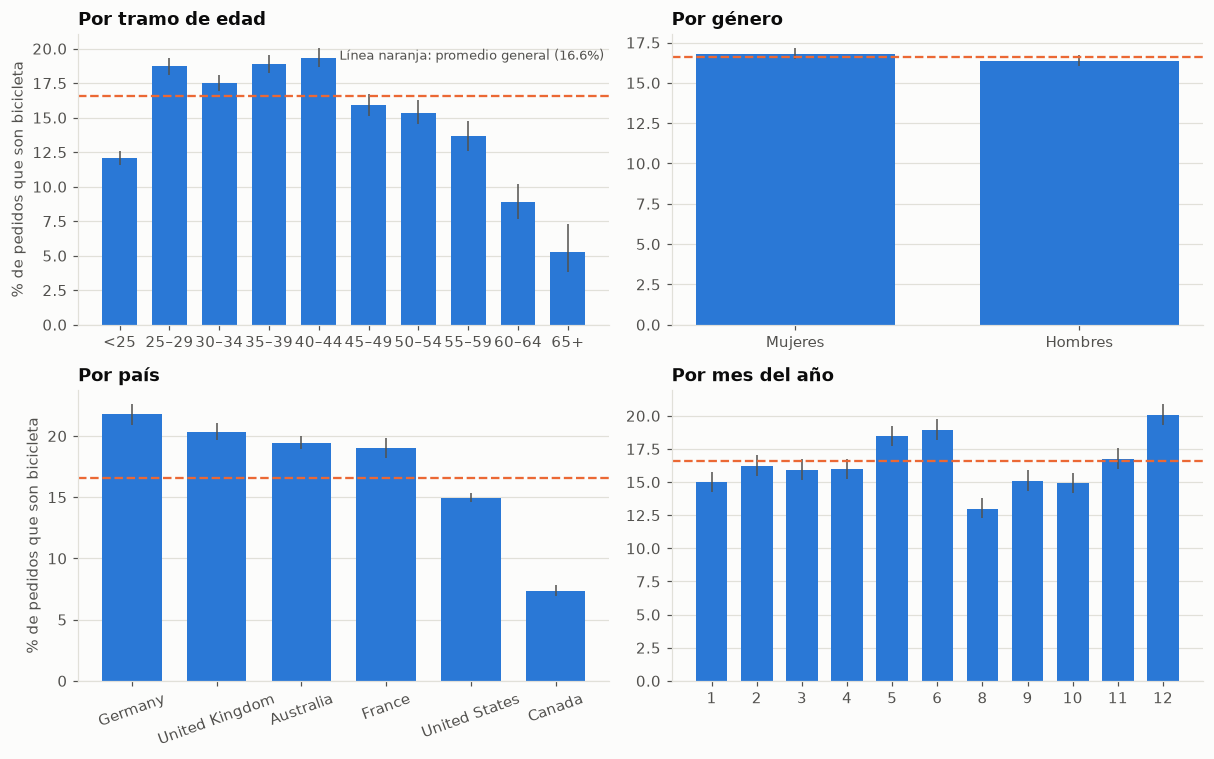

In [10]:
def wilson(k, n, z=1.96):
    # Intervalo de confianza de Wilson para una proporción.
    p = k / n
    den = 1 + z**2 / n
    centro = (p + z**2 / (2 * n)) / den
    mitad = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return centro - mitad, centro + mitad

def tabla_tasa(col):
    t = datos.groupby(col, observed=True)[TARGET].agg(["sum", "count"]).rename(columns={"sum": "bicis", "count": "pedidos"})
    t["tasa"] = t["bicis"] / t["pedidos"]
    t["lo"], t["hi"] = wilson(t["bicis"], t["pedidos"])
    return t

TASA_GLOBAL = datos[TARGET].mean()
BANDAS = [0, 24, 29, 34, 39, 44, 49, 54, 59, 64, 120]
ETIQ = ["<25", "25–29", "30–34", "35–39", "40–44", "45–49", "50–54", "55–59", "60–64", "65+"]
datos["banda_edad"] = pd.cut(datos["edad"], BANDAS, labels=ETIQ)

def barras(ax, t, color=AZUL, titulo="", rot=0, horizontal=False):
    pos = np.arange(len(t))
    err = np.vstack([t["tasa"] - t["lo"], t["hi"] - t["tasa"]]) * 100
    if horizontal:
        ax.barh(pos, t["tasa"] * 100, xerr=err, color=color, height=0.65, error_kw={"ecolor": TINTA_2, "lw": 1})
        ax.set_yticks(pos, t.index); ax.invert_yaxis(); ax.axvline(TASA_GLOBAL * 100, color=NARANJA, lw=1.5, ls="--")
        ax.grid(axis="y", visible=False)
    else:
        ax.bar(pos, t["tasa"] * 100, yerr=err, color=color, width=0.7, error_kw={"ecolor": TINTA_2, "lw": 1})
        ax.set_xticks(pos, t.index, rotation=rot); ax.axhline(TASA_GLOBAL * 100, color=NARANJA, lw=1.5, ls="--")
        ax.grid(axis="x", visible=False)
    ax.set_title(titulo)

fig, axs = plt.subplots(2, 2, figsize=(11, 7))
barras(axs[0, 0], tabla_tasa("banda_edad"), titulo="Por tramo de edad", rot=0)
barras(axs[0, 1], tabla_tasa("genero").rename(index={"F": "Mujeres", "M": "Hombres"}), titulo="Por género")
barras(axs[1, 0], tabla_tasa("pais").sort_values("tasa", ascending=False), titulo="Por país", rot=20)
barras(axs[1, 1], tabla_tasa("mes"), titulo="Por mes del año")
for a in axs[:, 0]: a.set_ylabel("% de pedidos que son bicicleta")
axs[0, 0].text(0.99, 0.95, f"Línea naranja: promedio general ({TASA_GLOBAL:.1%})", transform=axs[0, 0].transAxes, ha="right", va="top", fontsize=8.5, color=TINTA_2)
plt.tight_layout(); plt.show()

In [11]:
t_edad, t_gen, t_pais = tabla_tasa("banda_edad"), tabla_tasa("genero"), tabla_tasa("pais")
print("Tasa por género:", {k: f"{v:.1%}" for k, v in t_gen["tasa"].items()})
print(f"Tramo con mayor tasa: {t_edad['tasa'].idxmax()} ({t_edad['tasa'].max():.1%}); menor: {t_edad['tasa'].idxmin()} ({t_edad['tasa'].min():.1%})")
print(f"País con mayor tasa: {t_pais['tasa'].idxmax()} ({t_pais['tasa'].max():.1%}); menor: {t_pais['tasa'].idxmin()} ({t_pais['tasa'].min():.1%})")

Tasa por género: {'F': '16.8%', 'M': '16.4%'}
Tramo con mayor tasa: 40–44 (19.4%); menor: 65+ (5.3%)
País con mayor tasa: Germany (21.8%); menor: Canada (7.4%)


**Lectura.** La edad y el país concentran la señal: la propensión se mantiene en torno al 18–19 % entre los 25 y los 44 años, desciende desde los 45 y cae de forma marcada a partir de los 55–60; Canadá y Estados Unidos están claramente por debajo de Europa y Australia. El género casi no discrimina por sí solo y el mes muestra una estacionalidad moderada (más alta en diciembre y en primavera-verano). El periodo estable abarca una sola estación de cada mes, por lo que la estacionalidad debe leerse con cautela. Se anticipa un poder predictivo **moderado**, que se evaluará con honestidad.

### 4.3 Dimensión geográfica: estados con volumen suficiente

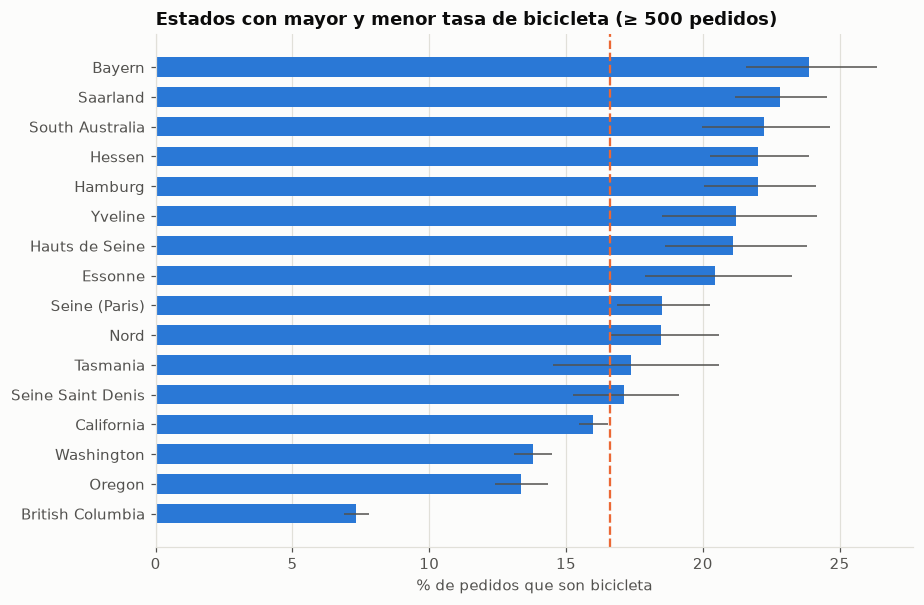

30 de 51 estados tienen menos de 500 pedidos: sus tasas son inestables y no se interpretan individualmente.


In [12]:
t_est = tabla_tasa("estado")
t_est = t_est[t_est["pedidos"] >= 500].sort_values("tasa", ascending=False)
n_est_total, n_est_peq = datos["estado"].nunique(), int((datos["estado"].value_counts() < 500).sum())
sel = pd.concat([t_est.head(8), t_est.tail(8)])
fig, ax = plt.subplots(figsize=(8.5, 5.6))
barras(ax, sel, titulo="Estados con mayor y menor tasa de bicicleta (≥ 500 pedidos)", horizontal=True)
ax.set_xlabel("% de pedidos que son bicicleta"); plt.tight_layout(); plt.show()
print(f"{n_est_peq} de {n_est_total} estados tienen menos de 500 pedidos: sus tasas son inestables y no se interpretan individualmente.")

Existe una dispersión geográfica amplia incluso dentro de un mismo país, lo que justifica incluir el **estado** como predictor además del país. Los estados con pocos pedidos se aprovechan solo a través del modelo, no como conclusiones individuales.

## 5. Diseño experimental

**Partición.** Se reserva el 20 % de los grupos como **conjunto de prueba**, que no se utiliza para ninguna decisión de modelado (ni para seleccionar variables ni para ajustar hiperparámetros) y solo sirve para el reporte final. El 80 % restante (entrenamiento) se usa con **validación cruzada estratificada por grupos** de 5 pliegues. Para comparar candidatos se repite la validación con dos particiones distintas (10 evaluaciones por modelo); el ajuste de hiperparámetros usa una tercera partición independiente.

**Métrica principal.** PR-AUC (*average precision*), complementada con ROC-AUC y *log-loss*. Con una prevalencia cercana al 17 %, la exactitud (*accuracy*) no es informativa: un modelo que siempre predice "no es bicicleta" acertaría el 83 % de las veces sin aportar nada.

In [13]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
idx_tr, idx_te = next(gss.split(datos, groups=datos["grupo"]))
train = datos.iloc[idx_tr].reset_index(drop=True)
test = datos.iloc[idx_te].reset_index(drop=True)
assert set(train["grupo"]).isdisjoint(test["grupo"]), "Hay grupos compartidos entre entrenamiento y prueba"

X_train, y_train, g_train = train[FEATURES], train[TARGET].to_numpy(), train["grupo"].to_numpy()
X_test, y_test, g_test = test[FEATURES], test[TARGET].to_numpy(), test["grupo"].to_numpy()

resumen = pd.DataFrame(
    {
        "pedidos": [len(train), len(test)],
        "grupos": [train["grupo"].nunique(), test["grupo"].nunique()],
        "prevalencia": [y_train.mean(), y_test.mean()],
        "estados_no_vistos": [0, len(set(test["estado"]) - set(train["estado"]))],
    },
    index=["Entrenamiento", "Prueba"],
)
display(resumen.style.format({"pedidos": "{:,}", "grupos": "{:,}", "prevalencia": "{:.2%}"}))

FOLDS_ARBITRAJE = [
    f for s in (0, 1) for f in StratifiedGroupKFold(5, shuffle=True, random_state=s).split(X_train, y_train, g_train)
]
FOLDS_AJUSTE = list(StratifiedGroupKFold(5, shuffle=True, random_state=11).split(X_train, y_train, g_train))

,pedidos,grupos,prevalencia,estados_no_vistos
Entrenamiento,"77,251","15,456",16.69%,0
Prueba,"19,108","3,864",16.22%,3


## 6. Modelado

### 6.1 Candidatos y justificación

| Candidato | Papel | Justificación |
|---|---|---|
| **Línea base (prevalencia)** | Piso de referencia | Predice siempre la tasa global; por construcción tiene ROC-AUC = 0.5. |
| **Regresión logística** | Referencia interpretable | Coeficientes explicables y despliegue trivial. Asume efectos aditivos; la edad se modela con *splines* para capturar su efecto no lineal. |
| **Regresión logística + interacciones** | Mejor versión lineal | Añade cruces país × mes y estado × tramo de edad para comprobar cuánto se gana al permitir interacciones explícitas. |
| **HistGradientBoosting** (scikit-learn) | *Boosting* de referencia | Árboles potenciados por gradiente [Friedman, 2001] con histogramas y variables categóricas nativas. |
| **XGBoost** | *Boosting* | Implementación regularizada de referencia en competencias tabulares [Chen & Guestrin, 2016]. |
| **LightGBM** | *Boosting* | Crecimiento por hojas, manejo nativo de categóricas con partición óptima y entrenamiento muy rápido [Ke et al., 2017]. |
| **CatBoost** | *Boosting* | Estadísticos de destino ordenados para categóricas, diseñados para evitar fuga de destino [Prokhorenkova et al., 2018]. |
| **Mezcla LightGBM + CatBoost** | Ensamble | Promedio de probabilidades de dos familias de *boosting* con sesgos distintos. |

Los métodos de *boosting* sobre árboles son la elección natural aquí: las variables son mixtas (numéricas y categóricas con decenas de niveles), y la relación con el objetivo es no lineal e interactiva (la edad actúa de forma distinta según el mercado). Las redes neuronales no se consideran porque, con cinco variables y ~77 mil filas, no existe evidencia de que superen a los árboles potenciados en datos tabulares [Grinsztajn et al., 2022; Shwartz-Ziv & Armon, 2022].

**Criterio de selección (definido antes de ver los resultados).** Se elige el modelo con mayor PR-AUC en validación cruzada; si un modelo más simple o más rápido queda a menos de **0.002** de PR-AUC del mejor (menos de 1 % relativo, diferencia sin relevancia práctica), se prefiere el más simple. Así el modelo final no se elige solo por tener la métrica más alta, sino considerando también interpretabilidad, costo y facilidad de implementación.

In [14]:
# ---------- Utilidades de modelado ----------
def a_categorico(Xa, Xb):
    # Convierte las columnas de texto a categorías definidas con el vocabulario de entrenamiento.
    A, B = Xa.copy(), Xb.copy()
    for c in A.columns:
        if not pd.api.types.is_numeric_dtype(A[c]):
            dt = pd.CategoricalDtype(sorted(A[c].astype(str).unique()))
            A[c], B[c] = A[c].astype(str).astype(dt), B[c].astype(str).astype(dt)
    return A, B

def metricas(y, p):
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p), "Log-loss": log_loss(y, p)}

def cruces(X):
    # Variables de interacción para la regresión logística extendida.
    X = X.copy()
    X["mes"] = X["mes"].astype(str)
    X["pais_mes"] = X["pais"] + "|" + X["mes"]
    X["estado_tramo"] = X["estado"] + "|" + pd.cut(X["edad"], [0, 24, 34, 44, 54, 120], labels=False).astype(str)
    return X

def fit_baseline():
    def f(Xa, ya, Xb):
        return DummyClassifier(strategy="prior").fit(Xa, ya).predict_proba(Xb)[:, 1]
    return f

def fit_logit(interacciones=False, C=0.2):
    cols_cat = ["genero", "pais", "estado", "mes"] + (["pais_mes", "estado_tramo"] if interacciones else [])
    def f(Xa, ya, Xb):
        prep = cruces if interacciones else (lambda X: X.assign(mes=X["mes"].astype(str)))
        ct = ColumnTransformer(
            [("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=5), cols_cat),
             ("edad", SplineTransformer(n_knots=6, degree=3), ["edad"])]
        )
        m = make_pipeline(ct, LogisticRegression(C=C, max_iter=3000)).fit(prep(Xa), ya)
        return m.predict_proba(prep(Xb))[:, 1]
    return f

def fit_hgb():
    def f(Xa, ya, Xb):
        oe = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan)
        A, B = Xa.copy(), Xb.copy()
        A[CAT], B[CAT] = oe.fit_transform(A[CAT]), oe.transform(B[CAT])
        m = HistGradientBoostingClassifier(
            max_iter=200, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=100,
            categorical_features=[A.columns.get_loc(c) for c in CAT], random_state=SEED,
        ).fit(A, ya)
        return m.predict_proba(B)[:, 1]
    return f

def fit_xgb():
    def f(Xa, ya, Xb):
        A, B = a_categorico(Xa, Xb)
        m = xgb.XGBClassifier(
            n_estimators=300, learning_rate=0.03, max_depth=5, min_child_weight=10, subsample=0.8,
            colsample_bytree=0.8, reg_lambda=5, enable_categorical=True, max_cat_to_onehot=8,
            tree_method="hist", random_state=SEED, n_jobs=-1,
        ).fit(A, ya)
        return m.predict_proba(B)[:, 1]
    return f

PARAMS_LGBM_DEFECTO = dict(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=100,
                           subsample=0.8, subsample_freq=1, colsample_bytree=0.8, cat_smooth=30, min_data_per_group=50)

def fit_lgbm(params):
    def f(Xa, ya, Xb):
        A, B = a_categorico(Xa, Xb)
        m = lgb.LGBMClassifier(**params, random_state=SEED, verbose=-1, n_jobs=-1, deterministic=True, force_row_wise=True).fit(A, ya)
        return m.predict_proba(B)[:, 1]
    return f

def fit_catboost(depth=6, l2=5.0, iteraciones=500):
    def f(Xa, ya, Xb):
        A, B = Xa.copy(), Xb.copy()
        m = CatBoostClassifier(
            iterations=iteraciones, learning_rate=0.06, depth=depth, l2_leaf_reg=l2, cat_features=CAT,
            random_seed=SEED, verbose=0, thread_count=-1,
        ).fit(A, ya)
        return m.predict_proba(B)[:, 1]
    return f

def validar(fit_fn, folds, X=None, y=None):
    # Devuelve las métricas de cada pliegue y las predicciones fuera de muestra.
    X = X_train if X is None else X
    y = y_train if y is None else y
    filas, preds = [], []
    for a, b in folds:
        t0 = time.perf_counter()
        p = fit_fn(X.iloc[a], y[a], X.iloc[b])
        filas.append({**metricas(y[b], p), "segundos": time.perf_counter() - t0})
        preds.append(p)
    return pd.DataFrame(filas), preds

### 6.2 Ajuste de hiperparámetros de LightGBM con Optuna

Se emplea optimización bayesiana (estimador de Parzen estructurado en árbol, TPE) con 60 pruebas, que explora el espacio de forma más eficiente que una búsqueda en cuadrícula o aleatoria [Akiba et al., 2019; Bergstra et al., 2011]. El objetivo es la PR-AUC media en validación cruzada agrupada, sobre una partición distinta de la usada después para comparar modelos.

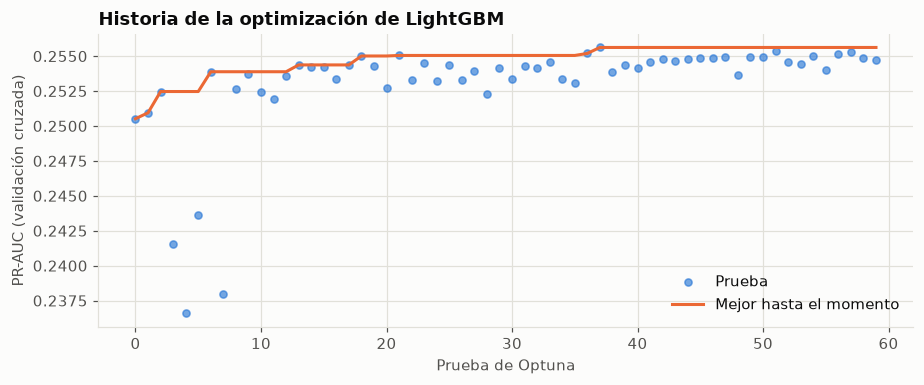

Mejor PR-AUC en el ajuste: 0.2556 | mediana de las pruebas: 0.2542 | mínimo: 0.2366
Hiperparámetros elegidos:
{
  "n_estimators": 268,
  "learning_rate": 0.0308,
  "num_leaves": 38,
  "min_child_samples": 20,
  "subsample": 0.8477,
  "colsample_bytree": 0.7329,
  "reg_lambda": 0.7774,
  "cat_smooth": 46.4449,
  "min_data_per_group": 58,
  "max_cat_to_onehot": 7,
  "subsample_freq": 1
}


In [15]:
def objetivo(trial):
    params = dict(
        n_estimators=trial.suggest_int("n_estimators", 100, 800),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        num_leaves=trial.suggest_int("num_leaves", 4, 48),
        min_child_samples=trial.suggest_int("min_child_samples", 20, 400),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
        subsample_freq=1,
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 30.0, log=True),
        cat_smooth=trial.suggest_float("cat_smooth", 1.0, 100.0, log=True),
        min_data_per_group=trial.suggest_int("min_data_per_group", 20, 300),
        max_cat_to_onehot=trial.suggest_int("max_cat_to_onehot", 2, 8),
    )
    res, _ = validar(fit_lgbm(params), FOLDS_AJUSTE)
    return res["PR-AUC"].mean()

estudio = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
estudio.optimize(objetivo, n_trials=60)
PARAMS_LGBM = {**estudio.best_params, "subsample_freq": 1}

pruebas = estudio.trials_dataframe()
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.scatter(pruebas["number"], pruebas["value"], s=22, color=AZUL, alpha=0.65, label="Prueba")
ax.plot(pruebas["number"], pruebas["value"].cummax(), color=NARANJA, lw=2, label="Mejor hasta el momento")
ax.set_xlabel("Prueba de Optuna"); ax.set_ylabel("PR-AUC (validación cruzada)")
ax.set_title("Historia de la optimización de LightGBM"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

print(f"Mejor PR-AUC en el ajuste: {estudio.best_value:.4f} | mediana de las pruebas: {pruebas['value'].median():.4f} "
      f"| mínimo: {pruebas['value'].min():.4f}")
print("Hiperparámetros elegidos:")
print(json.dumps({k: (round(v, 4) if isinstance(v, float) else v) for k, v in PARAMS_LGBM.items()}, indent=2))

La optimización mejora de forma modesta y rápida sobre la configuración inicial y luego se estabiliza: una señal de que el rendimiento está acotado por la **información disponible** (cinco variables) y no por los hiperparámetros.

### 6.3 Ajuste de la profundidad de CatBoost

Para que la comparación con CatBoost sea justa, se ajusta su profundidad en la misma partición de ajuste.

In [16]:
filas = []
for depth in (4, 6, 8):
    res, _ = validar(fit_catboost(depth=depth), FOLDS_AJUSTE)
    filas.append({"profundidad": depth, **res[["ROC-AUC", "PR-AUC", "Log-loss"]].mean().to_dict(), "segundos_por_ajuste": res["segundos"].mean()})
grid_cb = pd.DataFrame(filas).set_index("profundidad")
display(grid_cb)
PROF_CB = int(grid_cb["PR-AUC"].idxmax())
print(f"Profundidad elegida para CatBoost: {PROF_CB}")

,ROC-AUC,PR-AUC,Log-loss,segundos_por_ajuste
profundidad,,,,
4,0.6570,0.2543,0.4272,29.3259
6,0.6603,0.2553,0.4258,37.5930
8,0.6596,0.2536,0.4261,45.3796


Profundidad elegida para CatBoost: 6


### 6.4 Comparación de candidatos en validación cruzada

Todos los modelos se evalúan sobre los **mismos 10 pliegues** (5 pliegues × 2 particiones), de modo que las diferencias se pueden analizar de forma pareada.

In [17]:
CANDIDATOS = {
    "Línea base (prevalencia)": (fit_baseline(), 0),
    "Regresión logística": (fit_logit(False), 1),
    "Regresión logística + interacciones": (fit_logit(True), 1),
    "HistGradientBoosting": (fit_hgb(), 2),
    "XGBoost": (fit_xgb(), 2),
    "LightGBM (por defecto)": (fit_lgbm(PARAMS_LGBM_DEFECTO), 2),
    "LightGBM (Optuna)": (fit_lgbm(PARAMS_LGBM), 2),
    "CatBoost": (fit_catboost(depth=PROF_CB), 3),
}
cv_res, cv_pred = {}, {}
for nombre, (fn, _) in CANDIDATOS.items():
    cv_res[nombre], cv_pred[nombre] = validar(fn, FOLDS_ARBITRAJE)

# Mezcla: promedio de las probabilidades de LightGBM (Optuna) y CatBoost en cada pliegue.
filas = []
cv_pred["Mezcla LightGBM + CatBoost"] = [
    (a + b) / 2 for a, b in zip(cv_pred["LightGBM (Optuna)"], cv_pred["CatBoost"])
]
for (_, idx_val), p in zip(FOLDS_ARBITRAJE, cv_pred["Mezcla LightGBM + CatBoost"]):
    filas.append({**metricas(y_train[idx_val], p), "segundos": np.nan})
cv_res["Mezcla LightGBM + CatBoost"] = pd.DataFrame(filas)
cv_res["Mezcla LightGBM + CatBoost"]["segundos"] = (
    cv_res["LightGBM (Optuna)"]["segundos"] + cv_res["CatBoost"]["segundos"]
)
COMPLEJIDAD = {n: c for n, (_, c) in CANDIDATOS.items()} | {"Mezcla LightGBM + CatBoost": 4}

tabla_cv = pd.DataFrame(
    {
        n: {
            "ROC-AUC": r["ROC-AUC"].mean(), "± ROC": r["ROC-AUC"].std(),
            "PR-AUC": r["PR-AUC"].mean(), "± PR": r["PR-AUC"].std(),
            "Log-loss": r["Log-loss"].mean(), "Segundos por ajuste": r["segundos"].mean(),
        }
        for n, r in cv_res.items()
    }
).T.sort_values("PR-AUC", ascending=False)
display(tabla_cv.style.format("{:.4f}", subset=["ROC-AUC", "± ROC", "PR-AUC", "± PR", "Log-loss"])
        .format("{:.1f}", subset=["Segundos por ajuste"]).background_gradient(cmap=CMAP_SEC, subset=["PR-AUC"]))

,ROC-AUC,± ROC,PR-AUC,± PR,Log-loss,Segundos por ajuste
Mezcla LightGBM + CatBoost,0.6625,0.0052,0.2581,0.0066,0.4256,40.2
CatBoost,0.6600,0.0053,0.2567,0.0065,0.4259,39.4
LightGBM (Optuna),0.6612,0.0052,0.2562,0.0063,0.4263,0.8
LightGBM (por defecto),0.6569,0.0051,0.2545,0.0060,0.4277,0.7
HistGradientBoosting,0.6552,0.0057,0.2521,0.0058,0.4277,1.4
XGBoost,0.6556,0.0051,0.2516,0.0066,0.4283,1.1
Regresión logística + interacciones,0.6218,0.0059,0.2283,0.0042,0.4374,0.9
Regresión logística,0.6101,0.0058,0.2191,0.0038,0.4396,0.5
Línea base (prevalencia),0.5000,0.0000,0.1669,0.0001,0.4509,0.0


Mejor PR-AUC: Mezcla LightGBM + CatBoost (0.2581)
Candidatos a menos de 0.002: ['Mezcla LightGBM + CatBoost', 'CatBoost', 'LightGBM (Optuna)']
Modelo seleccionado: LightGBM (Optuna)



,Δ PR-AUC medio,Pliegues donde supera al seleccionado
Mezcla LightGBM + CatBoost,+0.0019,9.000000
CatBoost,+0.0005,6.000000
LightGBM (por defecto),-0.0018,1.000000
HistGradientBoosting,-0.0041,0.000000
XGBoost,-0.0046,0.000000
Regresión logística + interacciones,-0.0279,0.000000
Regresión logística,-0.0371,0.000000
Línea base (prevalencia),-0.0894,0.000000


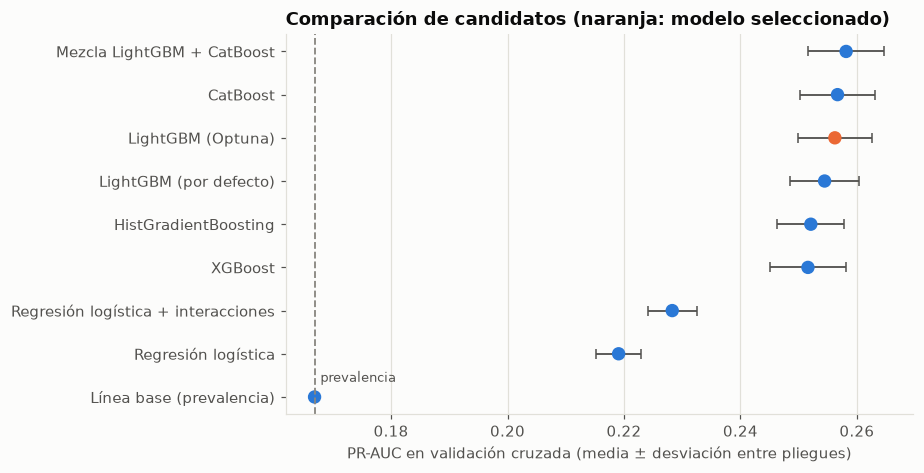

In [18]:
mejor = tabla_cv["PR-AUC"].idxmax()
elegibles = [n for n in tabla_cv.index if tabla_cv.loc[mejor, "PR-AUC"] - tabla_cv.loc[n, "PR-AUC"] < 0.002]
SELECCIONADO = sorted(elegibles, key=lambda n: (COMPLEJIDAD[n], -tabla_cv.loc[n, "PR-AUC"]))[0]

# Diferencias pareadas contra el modelo seleccionado (mismos pliegues).
dif = pd.DataFrame(
    {
        n: {
            "Δ PR-AUC medio": (cv_res[n]["PR-AUC"] - cv_res[SELECCIONADO]["PR-AUC"]).mean(),
            "Pliegues donde supera al seleccionado": int((cv_res[n]["PR-AUC"] > cv_res[SELECCIONADO]["PR-AUC"]).sum()),
        }
        for n in tabla_cv.index if n != SELECCIONADO
    }
).T
print(f"Mejor PR-AUC: {mejor} ({tabla_cv.loc[mejor, 'PR-AUC']:.4f})")
print(f"Candidatos a menos de 0.002: {elegibles}")
print(f"Modelo seleccionado: {SELECCIONADO}\n")
display(dif.style.format({"Δ PR-AUC medio": "{:+.4f}"}))

orden = tabla_cv.sort_values("PR-AUC")
fig, ax = plt.subplots(figsize=(8.5, 4.4))
ypos = np.arange(len(orden))
colores = [NARANJA if n == SELECCIONADO else AZUL for n in orden.index]
ax.errorbar(orden["PR-AUC"], ypos, xerr=orden["± PR"], fmt="none", ecolor=TINTA_2, elinewidth=1.2, capsize=3, zorder=1)
ax.scatter(orden["PR-AUC"], ypos, s=60, c=colores, zorder=2)
ax.axvline(y_train.mean(), color=GRIS, ls="--", lw=1.2); ax.text(y_train.mean() + 0.001, 0.35, "prevalencia", color=TINTA_2, fontsize=8.5)
ax.set_yticks(ypos, orden.index); ax.set_xlabel("PR-AUC en validación cruzada (media ± desviación entre pliegues)")
ax.set_title("Comparación de candidatos (naranja: modelo seleccionado)"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Lectura.**

- **Los métodos de *boosting* convergen.** HistGradientBoosting, XGBoost, LightGBM y CatBoost quedan dentro de una banda de unas 0.006 unidades de PR-AUC, comparable a la variación entre pliegues. La regresión logística, aun con interacciones explícitas, queda claramente por debajo (≈ 0.03 de PR-AUC), lo que confirma que existen interacciones no lineales (por ejemplo, edad × mercado) que los árboles capturan automáticamente.
- **Se alcanzó el techo de información.** Que algoritmos de naturaleza distinta, ajustados y regularizados de forma independiente, lleguen al mismo nivel indica que el límite no está en el algoritmo sino en la información disponible: cinco variables de perfil.
- **Aplicación del criterio de selección.** La mezcla LightGBM + CatBoost tiene la PR-AUC más alta, pero su ventaja sobre LightGBM ajustado es de apenas ≈ 0.002 (< 1 % relativo) y exige entrenar y mantener dos librerías, con un costo de entrenamiento unas 25 veces mayor. CatBoost empata en métrica pero también es unas 25 veces más lento. **LightGBM ajustado con Optuna** es el modelo más simple y rápido dentro de la tolerancia definida, por lo que es el seleccionado: predice en milisegundos, soporta variables categóricas de forma nativa y permite explicabilidad exacta con SHAP (*TreeExplainer*).

### 6.5 Ingeniería de variables y ablación

Se evalúa, con el modelo seleccionado y los mismos pliegues, (a) cuánto aporta cada variable original quitándola y (b) si variables derivadas aportan información adicional. Un cambio se considera relevante solo si supera la variación entre pliegues.

In [19]:
def enriquecer(X):
    X = X.copy()
    X["tramo_edad"] = pd.cut(X["edad"], [0, 24, 34, 44, 54, 120], labels=["<25", "25-34", "35-44", "45-54", "55+"]).astype(str)
    X["pais_estado"] = X["pais"] + "|" + X["estado"]
    X["genero_tramo"] = X["genero"] + "|" + X["tramo_edad"]
    X["mes_sen"], X["mes_cos"] = np.sin(2 * np.pi * X["mes"] / 12), np.cos(2 * np.pi * X["mes"] / 12)
    X["trimestre"] = (X["mes"] - 1) // 3
    X["edad_x_mes"] = X["edad"] * X["mes"]
    return X

X_train_ext = enriquecer(X_train)
variantes = {
    "Modelo base (5 variables)": FEATURES,
    "− edad": [c for c in FEATURES if c != "edad"],
    "− género": [c for c in FEATURES if c != "genero"],
    "− país": [c for c in FEATURES if c != "pais"],
    "− estado": [c for c in FEATURES if c != "estado"],
    "− mes": [c for c in FEATURES if c != "mes"],
    "+ tramo de edad": FEATURES + ["tramo_edad"],
    "+ país|estado": FEATURES + ["pais_estado"],
    "+ género × tramo de edad": FEATURES + ["genero_tramo"],
    "+ mes cíclico (sen/cos)": FEATURES + ["mes_sen", "mes_cos"],
    "+ trimestre": FEATURES + ["trimestre"],
    "+ edad × mes": FEATURES + ["edad_x_mes"],
}
filas = {}
for nombre, cols in variantes.items():
    res, _ = validar(fit_lgbm(PARAMS_LGBM), FOLDS_ARBITRAJE, X=X_train_ext[cols])
    filas[nombre] = {"ROC-AUC": res["ROC-AUC"].mean(), "PR-AUC": res["PR-AUC"].mean(), "Log-loss": res["Log-loss"].mean()}
ablacion = pd.DataFrame(filas).T
ablacion["Δ ROC-AUC vs base"] = ablacion["ROC-AUC"] - ablacion.loc["Modelo base (5 variables)", "ROC-AUC"]
ablacion["Δ PR-AUC vs base"] = ablacion["PR-AUC"] - ablacion.loc["Modelo base (5 variables)", "PR-AUC"]
display(ablacion.style.format("{:.4f}").format("{:+.4f}", subset=["Δ ROC-AUC vs base", "Δ PR-AUC vs base"]))
variacion_pliegues = cv_res["LightGBM (Optuna)"]["ROC-AUC"].std()
print(f"Desviación del ROC-AUC entre pliegues: {variacion_pliegues:.4f}")

,ROC-AUC,PR-AUC,Log-loss,Δ ROC-AUC vs base,Δ PR-AUC vs base
Modelo base (5 variables),0.6612,0.2562,0.4263,+0.0000,+0.0000
− edad,0.5929,0.2114,0.4430,-0.0683,-0.0449
− género,0.6569,0.2536,0.4280,-0.0043,-0.0026
− país,0.6560,0.2520,0.4284,-0.0052,-0.0043
− estado,0.6576,0.2536,0.4277,-0.0036,-0.0026
− mes,0.6441,0.2491,0.4319,-0.0172,-0.0071
+ tramo de edad,0.6611,0.2561,0.4266,-0.0001,-0.0001
+ país|estado,0.6591,0.2545,0.4272,-0.0021,-0.0017
+ género × tramo de edad,0.6603,0.2557,0.4266,-0.0010,-0.0005
+ mes cíclico (sen/cos),0.6594,0.2543,0.4269,-0.0018,-0.0020


Desviación del ROC-AUC entre pliegues: 0.0052


**Lectura.**

- **Edad y mes son indispensables:** quitar la edad reduce el ROC-AUC en ≈ 0.07 y quitar el mes en ≈ 0.017.
- **País, estado y género aportan poco de forma individual, pero consistente** (≈ 0.004–0.005 de ROC-AUC cada uno, del orden de una desviación entre pliegues). País y estado son parcialmente redundantes: al quitar uno, el otro compensa gran parte de la información geográfica, por lo que su aporte conjunto es mayor que el de cada uno por separado. Se conservan ambos porque el país agrupa estados con pocos pedidos y ayuda a los árboles a compartir información.
- **Ninguna variable derivada mejora el modelo.** Todas quedan por debajo o dentro de la variación entre pliegues: los árboles ya construyen internamente tramos e interacciones. Se conserva por parsimonia el conjunto original de cinco variables, que además coincide exactamente con lo disponible antes de la compra.

## 7. Evaluación final en datos no vistos

El modelo seleccionado se reentrena con todo el conjunto de entrenamiento y se evalúa **una sola vez** en el conjunto de prueba. Se reportan también la línea base y la regresión logística para contextualizar. Los intervalos de confianza se obtienen por *bootstrap por grupos* (se remuestrean grupos completos, respetando la dependencia entre pedidos gemelos) [Efron & Tibshirani, 1993].

In [20]:
assert SELECCIONADO == "LightGBM (Optuna)", "El resto del cuaderno interpreta un modelo LightGBM"

def ajustar_final():
    A, B = a_categorico(X_train, X_test)
    modelo = lgb.LGBMClassifier(**PARAMS_LGBM, random_state=SEED, verbose=-1, n_jobs=-1, deterministic=True, force_row_wise=True)
    modelo.fit(A, y_train)
    return modelo, A, B

modelo, A_train, A_test = ajustar_final()
p_test = modelo.predict_proba(A_test)[:, 1]
p_logit = fit_logit(False)(X_train, y_train, X_test)
p_base = fit_baseline()(X_train, y_train, X_test)

# Bootstrap por grupos
rng = np.random.default_rng(SEED)
orden_g = np.argsort(g_test, kind="stable")
grupos_u, inicio = np.unique(g_test[orden_g], return_index=True)
cortes = np.split(orden_g, inicio[1:])
B_REP = 600
boot = {"modelo": [], "logit": [], "dif_roc": [], "dif_pr": []}
for _ in range(B_REP):
    ids = np.concatenate([cortes[i] for i in rng.integers(0, len(cortes), len(cortes))])
    yb = y_test[ids]
    r_m, r_l = roc_auc_score(yb, p_test[ids]), roc_auc_score(yb, p_logit[ids])
    a_m, a_l = average_precision_score(yb, p_test[ids]), average_precision_score(yb, p_logit[ids])
    boot["modelo"].append((r_m, a_m)); boot["logit"].append((r_l, a_l))
    boot["dif_roc"].append(r_m - r_l); boot["dif_pr"].append(a_m - a_l)

def ic(v):
    return np.percentile(v, [2.5, 97.5])

filas = []
for nombre, p, clave in [("Línea base (prevalencia)", p_base, None), ("Regresión logística", p_logit, "logit"),
                         ("LightGBM (Optuna) — modelo final", p_test, "modelo")]:
    m = metricas(y_test, p)
    fila = {"ROC-AUC": m["ROC-AUC"], "PR-AUC": m["PR-AUC"], "Log-loss": m["Log-loss"], "Brier": brier_score_loss(y_test, p)}
    if clave:
        arr = np.array(boot[clave])
        fila["IC95% ROC-AUC"] = f"{ic(arr[:, 0])[0]:.3f}–{ic(arr[:, 0])[1]:.3f}"
        fila["IC95% PR-AUC"] = f"{ic(arr[:, 1])[0]:.3f}–{ic(arr[:, 1])[1]:.3f}"
    filas.append(pd.Series(fila, name=nombre))
tabla_test = pd.DataFrame(filas)
display(tabla_test.style.format({"ROC-AUC": "{:.4f}", "PR-AUC": "{:.4f}", "Log-loss": "{:.4f}", "Brier": "{:.4f}"}))

d_roc, d_pr = np.array(boot["dif_roc"]), np.array(boot["dif_pr"])
print(f"Mejora sobre la regresión logística: ROC-AUC {np.mean(d_roc):+.4f} (IC95% {ic(d_roc)[0]:+.4f} a {ic(d_roc)[1]:+.4f}); "
      f"PR-AUC {np.mean(d_pr):+.4f} (IC95% {ic(d_pr)[0]:+.4f} a {ic(d_pr)[1]:+.4f})")

,ROC-AUC,PR-AUC,Log-loss,Brier,IC95% ROC-AUC,IC95% PR-AUC
Línea base (prevalencia),0.5000,0.1622,0.4434,0.1359,nan,nan
Regresión logística,0.6119,0.2147,0.4318,0.1331,0.600–0.625,0.206–0.225
LightGBM (Optuna) — modelo final,0.6646,0.2507,0.4180,0.1298,0.654–0.676,0.240–0.262


Mejora sobre la regresión logística: ROC-AUC +0.0527 (IC95% +0.0442 a +0.0618); PR-AUC +0.0360 (IC95% +0.0277 a +0.0446)


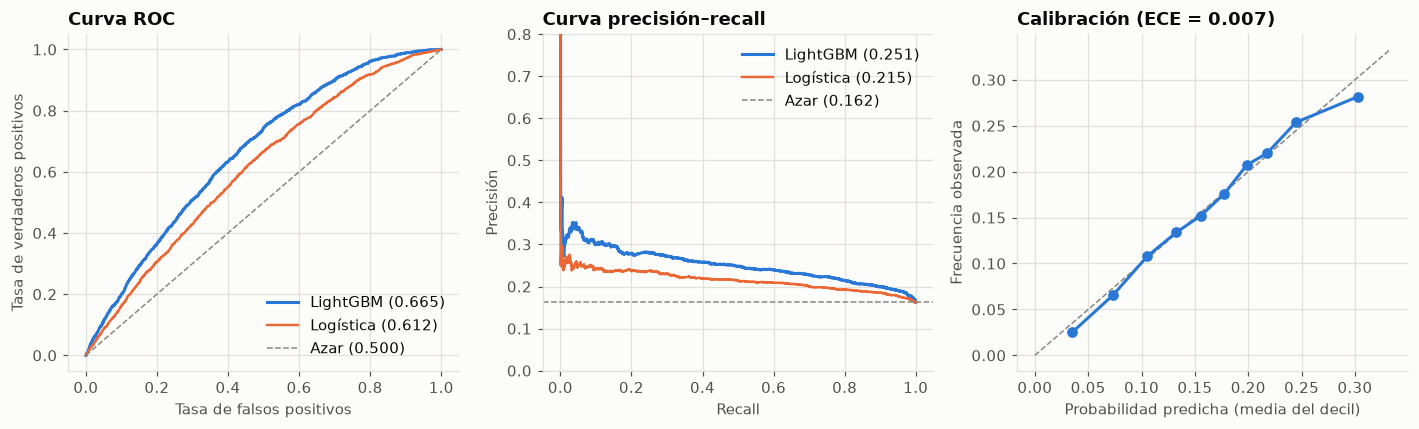

In [21]:
fpr, tpr, _ = roc_curve(y_test, p_test)
fpr_l, tpr_l, _ = roc_curve(y_test, p_logit)
prec, rec, _ = precision_recall_curve(y_test, p_test)
prec_l, rec_l, _ = precision_recall_curve(y_test, p_logit)

# Calibración por deciles de probabilidad predicha
cal = pd.DataFrame({"p": p_test, "y": y_test})
cal["bin"] = pd.qcut(cal["p"], 10, duplicates="drop")
cal = cal.groupby("bin", observed=True).agg(p=("p", "mean"), y=("y", "mean"), n=("y", "size"))
ece = float((cal["n"] * (cal["p"] - cal["y"]).abs()).sum() / cal["n"].sum())

fig, axs = plt.subplots(1, 3, figsize=(13, 4))
ax = axs[0]
ax.plot(fpr, tpr, color=AZUL, lw=2, label=f"LightGBM ({roc_auc_score(y_test, p_test):.3f})")
ax.plot(fpr_l, tpr_l, color=NARANJA, lw=1.6, label=f"Logística ({roc_auc_score(y_test, p_logit):.3f})")
ax.plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1, label="Azar (0.500)")
ax.set_xlabel("Tasa de falsos positivos"); ax.set_ylabel("Tasa de verdaderos positivos"); ax.set_title("Curva ROC"); ax.legend(loc="lower right")
ax = axs[1]
ax.plot(rec, prec, color=AZUL, lw=2, label=f"LightGBM ({average_precision_score(y_test, p_test):.3f})")
ax.plot(rec_l, prec_l, color=NARANJA, lw=1.6, label=f"Logística ({average_precision_score(y_test, p_logit):.3f})")
ax.axhline(y_test.mean(), color=GRIS, ls="--", lw=1, label=f"Azar ({y_test.mean():.3f})")
ax.set_xlabel("Recall"); ax.set_ylabel("Precisión"); ax.set_title("Curva precisión–recall"); ax.legend(loc="upper right"); ax.set_ylim(0, 0.8)
ax = axs[2]
lim = max(cal["p"].max(), cal["y"].max()) * 1.1
ax.plot([0, lim], [0, lim], color=GRIS, ls="--", lw=1)
ax.plot(cal["p"], cal["y"], marker="o", color=AZUL, lw=2, ms=6)
ax.set_xlabel("Probabilidad predicha (media del decil)"); ax.set_ylabel("Frecuencia observada"); ax.set_title(f"Calibración (ECE = {ece:.3f})")
plt.tight_layout(); plt.show()

**Lectura.** El modelo mejora de forma clara a la línea base y a la regresión logística, con un intervalo de confianza de la diferencia que no incluye cero. El poder discriminativo es **moderado**, como era esperable al predecir una elección de producto con solo cinco variables de perfil. Las probabilidades están bien calibradas (la curva sigue la diagonal y el error de calibración esperado es inferior a 1 punto porcentual), por lo que pueden interpretarse como probabilidades y no solo como un orden. Los tres estados que aparecen solo en la prueba se tratan como categoría desconocida, que es el comportamiento esperado en producción ante un estado nuevo.

### 7.1 Valor de negocio: *lift* y curva de ganancias acumuladas

El stakeholder no necesita acertar cada pedido sino **priorizar**: si contacta solo al *k %* de perfiles mejor puntuados, ¿qué fracción de las compras de bicicleta y de la ganancia captura?

,Precisión (% bicicleta),Lift,% de bicicletas capturadas,% de la ganancia de bicicletas,% de la ganancia total
% de pedidos contactados,,,,,
10.000000,28.0,1.73,17.3,16.2,12.2
20.000000,26.7,1.65,33.0,31.1,24.1
30.000000,25.2,1.55,46.5,46.6,36.7
40.000000,24.0,1.48,59.3,60.3,48.4
50.000000,22.8,1.40,70.2,70.7,58.8


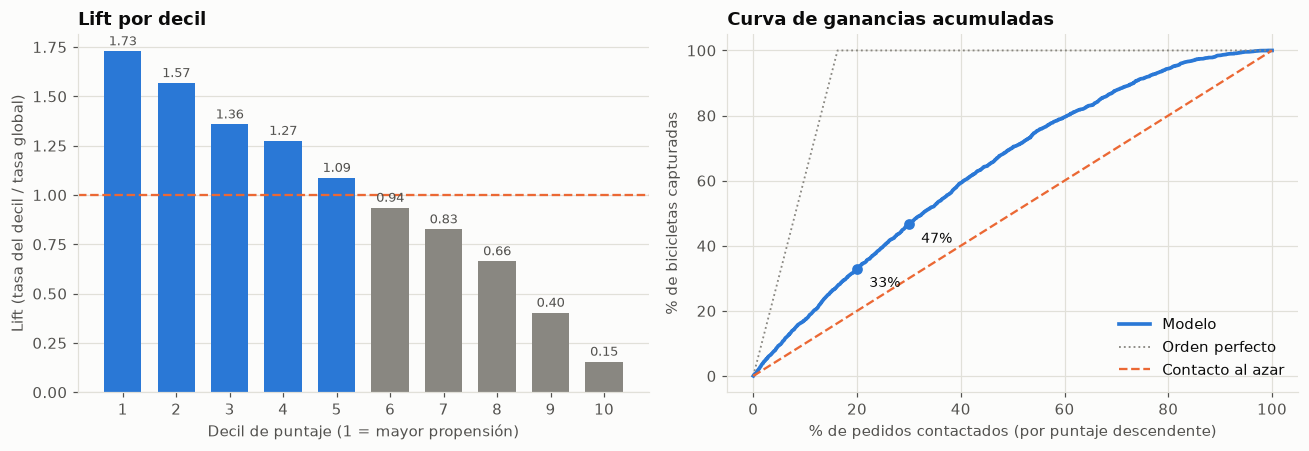

In [22]:
test_eval = test[["es_bicicleta", "ganancia"]].copy()
test_eval["p"] = p_test
test_eval = test_eval.sort_values("p", ascending=False).reset_index(drop=True)
n = len(test_eval)
bicis_tot = test_eval["es_bicicleta"].sum()
ganancia_bici_tot = test_eval.loc[test_eval["es_bicicleta"] == 1, "ganancia"].sum()
ganancia_tot = test_eval["ganancia"].sum()

def captura(fraccion):
    top = test_eval.iloc[: int(round(n * fraccion))]
    return {
        "% de pedidos contactados": fraccion * 100,
        "Precisión (% bicicleta)": top["es_bicicleta"].mean() * 100,
        "Lift": top["es_bicicleta"].mean() / y_test.mean(),
        "% de bicicletas capturadas": top["es_bicicleta"].sum() / bicis_tot * 100,
        "% de la ganancia de bicicletas": top.loc[top["es_bicicleta"] == 1, "ganancia"].sum() / ganancia_bici_tot * 100,
        "% de la ganancia total": top["ganancia"].sum() / ganancia_tot * 100,
    }

ganancias = pd.DataFrame([captura(f) for f in (0.1, 0.2, 0.3, 0.4, 0.5)]).set_index("% de pedidos contactados")
display(ganancias.style.format("{:.1f}").format("{:.2f}", subset=["Lift"]))

# Lift por decil
test_eval["decil"] = pd.qcut(np.arange(n), 10, labels=range(1, 11))
dec = test_eval.groupby("decil", observed=True).agg(tasa=("es_bicicleta", "mean"), p=("p", "mean"))
dec["lift"] = dec["tasa"] / y_test.mean()

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axs[0]
ax.bar(dec.index.astype(int), dec["lift"], color=[AZUL if v >= 1 else GRIS for v in dec["lift"]], width=0.7)
ax.axhline(1, color=NARANJA, ls="--", lw=1.5)
ax.set_xlabel("Decil de puntaje (1 = mayor propensión)"); ax.set_ylabel("Lift (tasa del decil / tasa global)")
ax.set_title("Lift por decil"); ax.set_xticks(range(1, 11)); ax.grid(axis="x", visible=False)
for xv, v in zip(dec.index.astype(int), dec["lift"]):
    ax.text(xv, v + 0.03, f"{v:.2f}", ha="center", fontsize=8.5, color=TINTA_2)
ax = axs[1]
frac = np.arange(1, n + 1) / n
cum_modelo = test_eval["es_bicicleta"].cumsum().to_numpy() / bicis_tot
ideal = np.minimum(frac * n / bicis_tot, 1)
ax.plot(frac * 100, cum_modelo * 100, color=AZUL, lw=2.4, label="Modelo")
ax.plot(frac * 100, ideal * 100, color=GRIS, lw=1.2, ls=":", label="Orden perfecto")
ax.plot([0, 100], [0, 100], color=NARANJA, lw=1.5, ls="--", label="Contacto al azar")
for f in (0.2, 0.3):
    v = captura(f)["% de bicicletas capturadas"]
    ax.scatter([f * 100], [v], color=AZUL, zorder=3); ax.annotate(f"{v:.0f}%", (f * 100, v), textcoords="offset points", xytext=(8, -12), fontsize=9)
ax.set_xlabel("% de pedidos contactados (por puntaje descendente)"); ax.set_ylabel("% de bicicletas capturadas")
ax.set_title("Curva de ganancias acumuladas"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

### 7.2 Chequeo de fuga y robustez

- **Predictores:** únicamente edad, género, país, estado y mes; ningún campo derivado del producto, precio, costo, cantidad, ingreso o ganancia.
- **Partición por grupos:** los registros gemelos nunca se reparten entre entrenamiento y prueba (verificado con una aserción).
- **Uso del conjunto de prueba:** una sola evaluación final; selección de variables, de modelo y de hiperparámetros se hicieron exclusivamente con validación cruzada sobre entrenamiento.
- **Concordancia:** el desempeño en prueba es consistente con el observado en validación cruzada, lo que indica ausencia de sobreajuste al conjunto de validación.

In [23]:
cv_final = cv_res["LightGBM (Optuna)"]
print(f"ROC-AUC  validación cruzada: {cv_final['ROC-AUC'].mean():.4f} ± {cv_final['ROC-AUC'].std():.4f}  |  prueba: {roc_auc_score(y_test, p_test):.4f}")
print(f"PR-AUC   validación cruzada: {cv_final['PR-AUC'].mean():.4f} ± {cv_final['PR-AUC'].std():.4f}  |  prueba: {average_precision_score(y_test, p_test):.4f}")

# Contraste de seguridad: ¿cuánto "mejoraría" el modelo si se filtrara el producto? (no se usa; solo ilustra la fuga)
fuga = df.loc[:, ["Unit_Price", "Unit_Cost"]].iloc[idx_tr].reset_index(drop=True)
fuga_te = df.loc[:, ["Unit_Price", "Unit_Cost"]].iloc[idx_te].reset_index(drop=True)
m_fuga = lgb.LGBMClassifier(n_estimators=100, verbose=-1, random_state=SEED).fit(fuga, y_train)
print(f"Referencia ilustrativa de fuga: usando solo precio y costo unitarios el ROC-AUC sería "
      f"{roc_auc_score(y_test, m_fuga.predict_proba(fuga_te)[:, 1]):.3f}; por eso esas variables se excluyen.")

ROC-AUC  validación cruzada: 0.6612 ± 0.0052  |  prueba: 0.6646
PR-AUC   validación cruzada: 0.2562 ± 0.0063  |  prueba: 0.2507
Referencia ilustrativa de fuga: usando solo precio y costo unitarios el ROC-AUC sería 1.000; por eso esas variables se excluyen.


## 8. Interpretación del modelo

### 8.1 Importancia por permutación

Mide cuánto cae el ROC-AUC en el conjunto de prueba al desordenar aleatoriamente cada variable (10 repeticiones) [Breiman, 2001; Fisher et al., 2019].

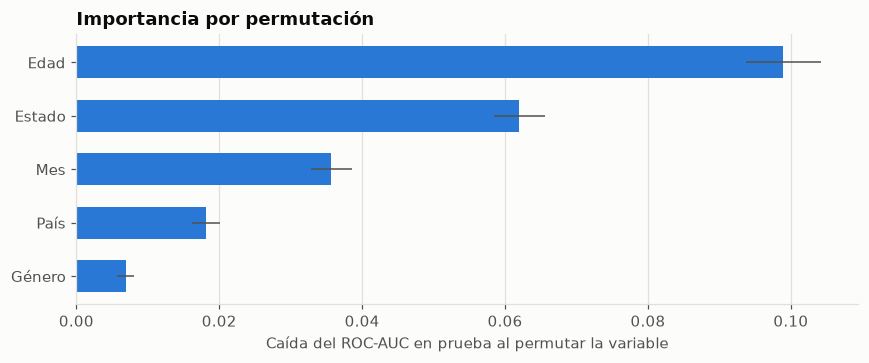

,Caída media de ROC-AUC,Desv. estándar
edad,0.0990,0.0052
estado,0.0620,0.0035
mes,0.0357,0.0028
pais,0.0181,0.0020
genero,0.0069,0.0012


In [24]:
perm = permutation_importance(modelo, A_test, y_test, scoring="roc_auc", n_repeats=10, random_state=SEED, n_jobs=1)
imp = pd.DataFrame({"media": perm.importances_mean, "sd": perm.importances_std}, index=FEATURES).sort_values("media")
nombres = {"edad": "Edad", "genero": "Género", "pais": "País", "estado": "Estado", "mes": "Mes"}
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh([nombres[i] for i in imp.index], imp["media"], xerr=imp["sd"], color=AZUL, height=0.6, error_kw={"ecolor": TINTA_2, "lw": 1})
ax.set_xlabel("Caída del ROC-AUC en prueba al permutar la variable"); ax.set_title("Importancia por permutación"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
display(imp.sort_values("media", ascending=False).rename(columns={"media": "Caída media de ROC-AUC", "sd": "Desv. estándar"}))

**Lectura.** La edad es la variable más influyente, seguida del estado y el mes; el país y el género aportan menos. La importancia por permutación del estado es alta porque, al desordenarlo sin reentrenar, el modelo pierde toda su información geográfica fina; en la ablación de la sección 6.5 (con reentrenamiento) su aporte es menor porque el país compensa parte de esa información. Ambas lecturas son compatibles: la **geografía importa**, pero estado y país son parcialmente intercambiables.

### 8.2 Dirección de los efectos con SHAP

Los valores SHAP descomponen cada predicción en la contribución de cada variable [Lundberg & Lee, 2017; Lundberg et al., 2020]; se expresan en escala logit (positivo = aumenta la probabilidad de bicicleta).

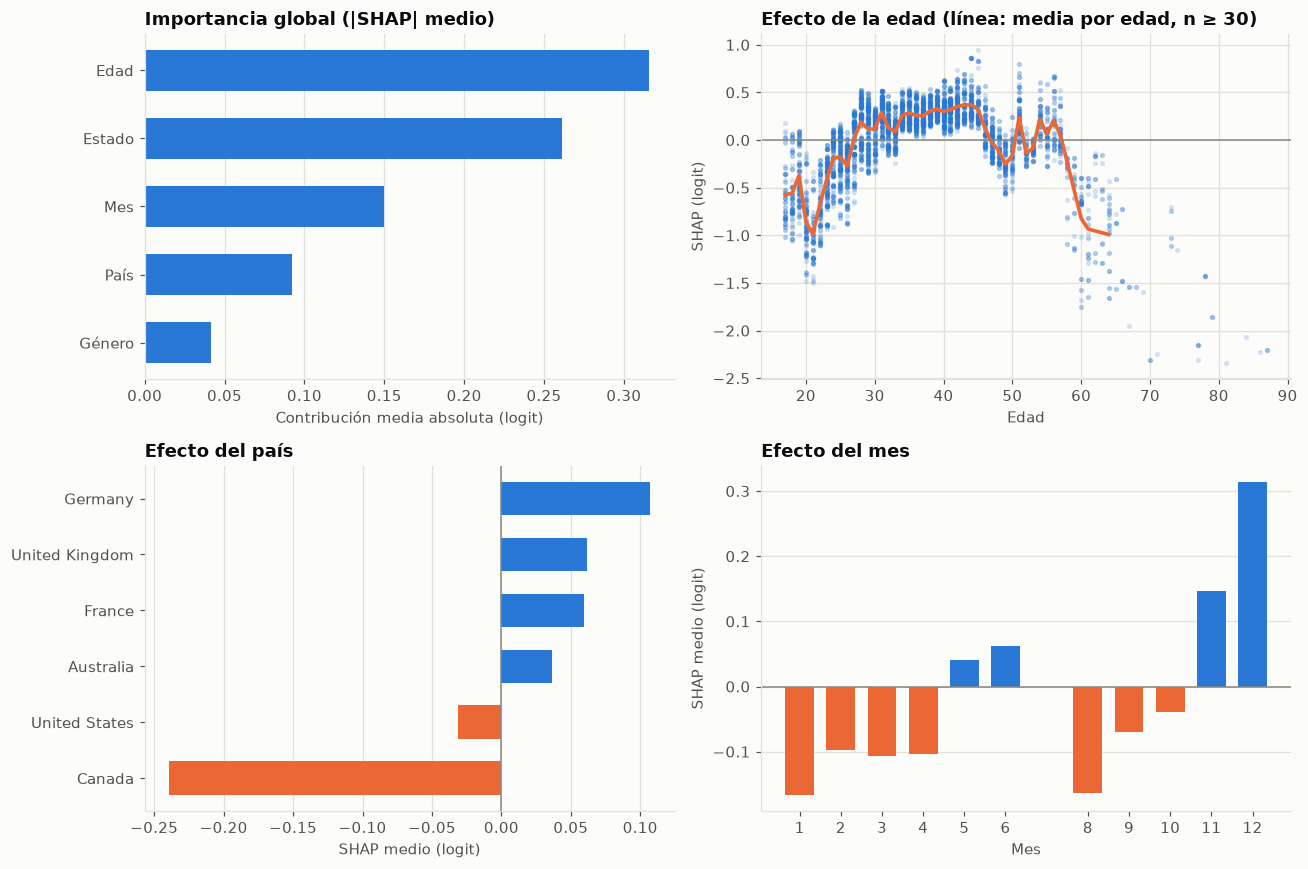

Efecto SHAP medio del género (logit): {'F': -0.0245, 'M': 0.0195}


In [25]:
muestra = A_test.sample(6000, random_state=SEED)
sv = shap.TreeExplainer(modelo).shap_values(muestra)
sv = sv[1] if isinstance(sv, list) else sv
shap_df = pd.DataFrame(sv, columns=FEATURES, index=muestra.index)

fig, axs = plt.subplots(2, 2, figsize=(12, 8))
# (a) importancia global
ax = axs[0, 0]
g = shap_df.abs().mean().sort_values()
ax.barh([nombres[i] for i in g.index], g.values, color=AZUL, height=0.6)
ax.set_title("Importancia global (|SHAP| medio)"); ax.set_xlabel("Contribución media absoluta (logit)"); ax.grid(axis="y", visible=False)
# (b) edad
ax = axs[0, 1]
edad_m = muestra["edad"].to_numpy()
ax.scatter(edad_m, shap_df["edad"], s=6, color=AZUL, alpha=0.15)
serie = pd.Series(shap_df["edad"].to_numpy()).groupby(edad_m)
perfil = serie.mean()[serie.size() >= 30]
ax.plot(perfil.index, perfil.values, color=NARANJA, lw=2.4); ax.axhline(0, color=GRIS, lw=1)
ax.set_title("Efecto de la edad (línea: media por edad, n ≥ 30)"); ax.set_xlabel("Edad"); ax.set_ylabel("SHAP (logit)")
# (c) país
ax = axs[1, 0]
sp = shap_df["pais"].groupby(muestra["pais"].astype(str)).mean().sort_values()
ax.barh(sp.index, sp.values, color=[NARANJA if v < 0 else AZUL for v in sp.values], height=0.6); ax.axvline(0, color=GRIS, lw=1)
ax.set_title("Efecto del país"); ax.set_xlabel("SHAP medio (logit)"); ax.grid(axis="y", visible=False)
# (d) mes
ax = axs[1, 1]
sm = shap_df["mes"].groupby(muestra["mes"].to_numpy()).mean()
ax.bar(sm.index, sm.values, color=[NARANJA if v < 0 else AZUL for v in sm.values], width=0.7); ax.axhline(0, color=GRIS, lw=1)
ax.set_xticks(sm.index); ax.set_title("Efecto del mes"); ax.set_xlabel("Mes"); ax.set_ylabel("SHAP medio (logit)"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

sg = shap_df["genero"].groupby(muestra["genero"].astype(str)).mean()
print("Efecto SHAP medio del género (logit):", {k: round(v, 4) for k, v in sg.items()})

**Lectura.**

- **Edad (la variable más influyente):** efecto no monótono. Los menores de 25 años empujan la predicción hacia "no bicicleta", la franja de 27 a 45 años hacia "bicicleta" y, a partir de los 55–60 años, el efecto se vuelve claramente negativo. Las oscilaciones entre edades vecinas y en edades muy altas (pocos pedidos) son ruido de estimación, no patrones interpretables.
- **País:** Canadá (y, en menor medida, Estados Unidos) reduce la propensión; Alemania, Reino Unido, Francia y Australia la aumentan.
- **Mes:** diciembre y noviembre son los de mayor propensión; agosto y enero, los de menor. No hay datos de julio.
- **Género:** contribución mínima (≈ ±0.02 en escala logit).

Estas conclusiones coinciden con la exploración descriptiva, lo que da confianza en que el modelo aprendió patrones reales y no artefactos.

## 9. Valor de negocio y recomendaciones por edad, género y mercado

Esta sección traduce el modelo y la exploración a decisiones comerciales. Para describir segmentos con **toda** la base se calcula, además, un puntaje de propensión *fuera de muestra* para cada pedido (validación cruzada por grupos con los hiperparámetros elegidos): ningún pedido se puntúa con un modelo que lo haya visto durante el entrenamiento.

In [26]:
datos["score"] = np.nan
for a, b in StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(datos, datos[TARGET], datos["grupo"]):
    p = fit_lgbm(PARAMS_LGBM)(datos.iloc[a][FEATURES], datos.iloc[a][TARGET].to_numpy(), datos.iloc[b][FEATURES])
    datos.loc[datos.index[b], "score"] = p
print(f"ROC-AUC fuera de muestra sobre toda la base: {roc_auc_score(datos[TARGET], datos['score']):.4f}")

TRAMOS = [0, 24, 34, 44, 54, 120]
TRAMO_ETIQ = ["<25", "25–34", "35–44", "45–54", "55+"]
datos["tramo"] = pd.cut(datos["edad"], TRAMOS, labels=TRAMO_ETIQ)
datos["genero_et"] = datos["genero"].map({"F": "Mujeres", "M": "Hombres"})

ROC-AUC fuera de muestra sobre toda la base: 0.6635


### 9.1 Mezcla de productos y ganancia por tramo de edad

¿Qué línea conviene empujar a cada edad? Se compara la composición de los pedidos y la ganancia media por pedido.

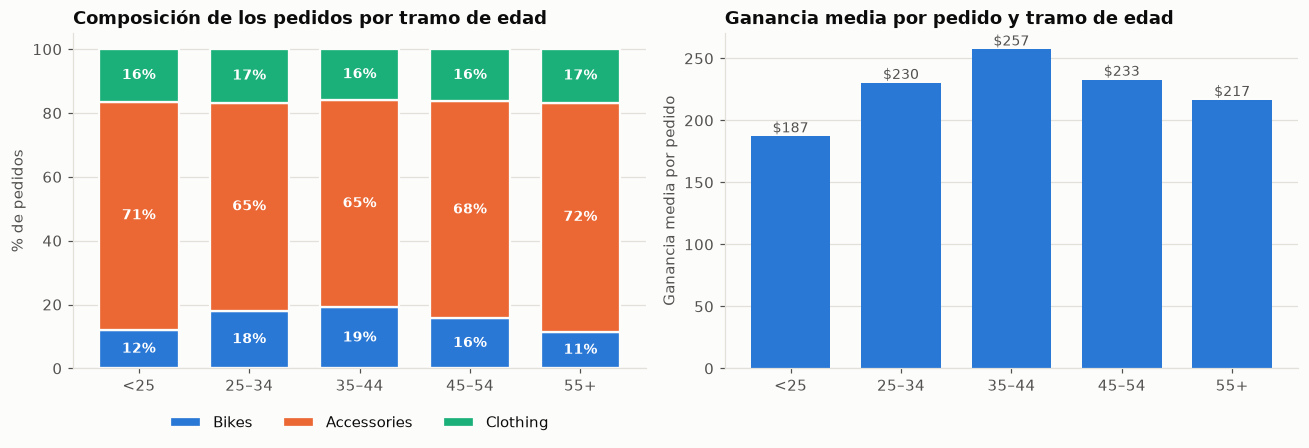

,Pedidos,% bicicleta,% accesorios,% ropa,Ganancia media ($),% de la ganancia que viene de bicicletas
tramo,,,,,,
<25,"15,154",12.1,71.5,16.4,187,45.2
25–34,"32,614",18.1,65.2,16.8,230,52.5
35–44,"27,050",19.1,65.0,15.9,257,55.7
45–54,"15,057",15.7,68.0,16.4,233,48.8
55+,"6,484",11.4,71.9,16.7,217,38.8


In [27]:
mezcla = datos.groupby(["tramo", "categoria"], observed=True).size().unstack(fill_value=0)
mezcla_pct = mezcla.div(mezcla.sum(axis=1), axis=0) * 100
gan_media = datos.groupby("tramo", observed=True)["ganancia"].mean()
gan_bici = datos[datos["categoria"] == "Bikes"].groupby("tramo", observed=True)["ganancia"].sum()
part_gan_bici = gan_bici / datos.groupby("tramo", observed=True)["ganancia"].sum() * 100

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axs[0]
base = np.zeros(len(mezcla_pct))
for cat, color in zip(["Bikes", "Accessories", "Clothing"], [AZUL, NARANJA, AQUA]):
    ax.bar(mezcla_pct.index.astype(str), mezcla_pct[cat], bottom=base, color=color, label=cat, width=0.72, edgecolor=FONDO, linewidth=1.5)
    for i, (b, v) in enumerate(zip(base, mezcla_pct[cat])):
        ax.text(i, b + v / 2, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    base += mezcla_pct[cat].values
ax.set_ylabel("% de pedidos"); ax.set_title("Composición de los pedidos por tramo de edad"); ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1)); ax.grid(axis="x", visible=False)
ax = axs[1]
ax.bar(gan_media.index.astype(str), gan_media.values, color=AZUL, width=0.72)
for i, v in enumerate(gan_media.values):
    ax.text(i, v + 3, f"${v:,.0f}", ha="center", fontsize=9, color=TINTA_2)
ax.set_ylabel("Ganancia media por pedido"); ax.set_title("Ganancia media por pedido y tramo de edad"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

resumen_edad = pd.DataFrame({"Pedidos": mezcla.sum(axis=1), "% bicicleta": mezcla_pct["Bikes"], "% accesorios": mezcla_pct["Accessories"],
                             "% ropa": mezcla_pct["Clothing"], "Ganancia media ($)": gan_media, "% de la ganancia que viene de bicicletas": part_gan_bici})
display(resumen_edad.style.format({"Pedidos": "{:,.0f}", "% bicicleta": "{:.1f}", "% accesorios": "{:.1f}", "% ropa": "{:.1f}",
                                   "Ganancia media ($)": "{:,.0f}", "% de la ganancia que viene de bicicletas": "{:.1f}"}))

### 9.2 Propensión por edad × país

Mapa de calor de la tasa observada de compra de bicicleta (celdas con al menos 200 pedidos). Sirve para decidir **dónde** y **a quién** dirigir la oferta de bicicletas.

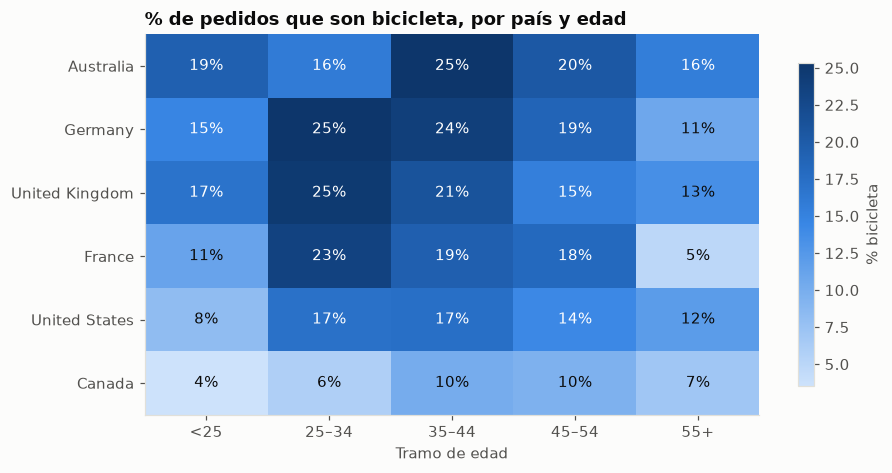

In [28]:
piv = datos.pivot_table(index="pais", columns="tramo", values=TARGET, aggfunc="mean", observed=True)
cnt = datos.pivot_table(index="pais", columns="tramo", values=TARGET, aggfunc="size", observed=True)
piv = piv.where(cnt >= 200)
piv = piv.loc[piv.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(8.5, 4.4))
im = ax.imshow(piv.values * 100, cmap=CMAP_SEC, aspect="auto")
ax.set_xticks(range(len(piv.columns)), piv.columns.astype(str)); ax.set_yticks(range(len(piv.index)), piv.index)
ax.grid(False)
vmax = np.nanmax(piv.values * 100)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.values[i, j] * 100
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0f}%", ha="center", va="center", fontsize=10, color="white" if v > vmax * 0.55 else TINTA)
ax.set_xlabel("Tramo de edad"); ax.set_title("% de pedidos que son bicicleta, por país y edad")
plt.colorbar(im, ax=ax, label="% bicicleta", shrink=0.85)
plt.tight_layout(); plt.show()

### 9.3 Género: ¿cambia la recomendación?

Se compara la tasa de bicicleta entre mujeres y hombres dentro de cada tramo de edad y país, con intervalos de confianza de la diferencia.

In [29]:
def dif_prop(sub):
    f, m = sub[sub["genero"] == "F"][TARGET], sub[sub["genero"] == "M"][TARGET]
    p1, p2, n1, n2 = f.mean(), m.mean(), len(f), len(m)
    se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    return pd.Series({"Mujeres (%)": p1 * 100, "Hombres (%)": p2 * 100, "Diferencia (pp)": (p1 - p2) * 100, "± IC95 (pp)": 1.96 * se * 100, "Pedidos": n1 + n2})

dif_global = dif_prop(datos).to_frame("General").T
dif_edad = datos.groupby("tramo", observed=True).apply(dif_prop)
dif_pais = datos.groupby("pais").apply(dif_prop)
tabla_gen = pd.concat([dif_global, dif_edad, dif_pais])
tabla_gen["¿Significativa?"] = np.where(tabla_gen["Diferencia (pp)"].abs() > tabla_gen["± IC95 (pp)"], "Sí", "No")
display(tabla_gen.style.format({"Mujeres (%)": "{:.1f}", "Hombres (%)": "{:.1f}", "Diferencia (pp)": "{:+.1f}", "± IC95 (pp)": "{:.1f}", "Pedidos": "{:,.0f}"}))

,Mujeres (%),Hombres (%),Diferencia (pp),± IC95 (pp),Pedidos,¿Significativa?
General,16.8,16.4,+0.4,0.5,"96,359",No
<25,10.6,13.3,-2.7,1.0,"15,154",Sí
25–34,18.4,17.8,+0.6,0.8,"32,614",No
35–44,20.1,18.1,+2.0,0.9,"27,050",Sí
45–54,15.2,16.2,-1.0,1.2,"15,057",No
55+,12.7,10.3,+2.4,1.6,"6,484",Sí
Australia,19.1,19.8,-0.7,1.1,"19,314",No
Canada,7.9,6.9,+0.9,0.9,"12,468",Sí
France,18.1,19.9,-1.8,1.6,"9,417",Sí
Germany,23.0,20.5,+2.4,1.7,"9,479",Sí


### 9.4 Mapa de prioridades: segmentos con mayor y menor propensión

Segmentos definidos por **país × tramo de edad × género** con al menos 300 pedidos, ordenados por la tasa observada de bicicleta, junto con el puntaje medio del modelo (fuera de muestra) y la ganancia media por pedido.

In [30]:
seg = datos.groupby(["pais", "tramo", "genero_et"], observed=True).agg(
    pedidos=(TARGET, "size"), tasa=(TARGET, "mean"), score=("score", "mean"), ganancia_media=("ganancia", "mean")
).reset_index()
seg = seg[seg["pedidos"] >= 300].copy()
seg["lift"] = seg["tasa"] / TASA_GLOBAL
seg = seg.rename(columns={"pais": "País", "tramo": "Edad", "genero_et": "Género", "pedidos": "Pedidos", "tasa": "Tasa observada",
                          "score": "Puntaje medio", "ganancia_media": "Ganancia media ($)", "lift": "Lift vs. promedio"})
fmt = {"Pedidos": "{:,.0f}", "Tasa observada": "{:.1%}", "Puntaje medio": "{:.1%}", "Ganancia media ($)": "{:,.0f}", "Lift vs. promedio": "{:.2f}"}
print(f"Segmentos con ≥ 300 pedidos: {len(seg)}  |  correlación tasa observada vs. puntaje medio: {seg['Tasa observada'].corr(seg['Puntaje medio']):.2f}")
print("\nSegmentos prioritarios para la oferta de bicicletas:")
display(seg.sort_values("Tasa observada", ascending=False).head(10).style.format(fmt).hide(axis="index"))
print("Segmentos donde conviene reorientar la oferta (accesorios y ropa):")
display(seg.sort_values("Tasa observada").head(10).style.format(fmt).hide(axis="index"))

Segmentos con ≥ 300 pedidos: 56  |  correlación tasa observada vs. puntaje medio: 0.99

Segmentos prioritarios para la oferta de bicicletas:


País,Edad,Género,Pedidos,Tasa observada,Puntaje medio,Ganancia media ($),Lift vs. promedio
Germany,25–34,Mujeres,"1,863",26.5%,26.3%,252,1.60
Germany,35–44,Mujeres,"1,297",25.6%,24.8%,298,1.54
Australia,35–44,Hombres,"2,363",25.5%,24.2%,248,1.54
Australia,35–44,Mujeres,"2,529",25.2%,24.5%,276,1.52
United Kingdom,25–34,Hombres,"2,094",24.8%,24.7%,264,1.50
United Kingdom,25–34,Mujeres,"1,918",24.6%,24.8%,299,1.48
France,25–34,Hombres,"1,997",24.2%,23.5%,226,1.46
Germany,25–34,Hombres,"1,921",23.9%,23.8%,255,1.44
France,25–34,Mujeres,"1,859",22.6%,22.8%,190,1.36
United Kingdom,35–44,Mujeres,"1,670",22.3%,21.7%,305,1.34


Segmentos donde conviene reorientar la oferta (accesorios y ropa):


País,Edad,Género,Pedidos,Tasa observada,Puntaje medio,Ganancia media ($),Lift vs. promedio
Canada,<25,Mujeres,898,2.7%,3.2%,112,0.16
Canada,<25,Hombres,"1,091",4.2%,3.9%,167,0.25
Canada,55+,Hombres,652,4.9%,6.0%,235,0.30
Canada,25–34,Mujeres,"1,891",5.0%,6.1%,184,0.30
United States,<25,Mujeres,"2,094",6.4%,7.2%,162,0.38
Canada,25–34,Hombres,"2,110",6.6%,6.1%,207,0.40
Canada,35–44,Hombres,"2,084",7.6%,8.7%,249,0.46
Canada,45–54,Mujeres,988,8.1%,9.0%,240,0.49
United States,<25,Hombres,"2,806",9.5%,9.1%,171,0.57
France,<25,Mujeres,760,10.5%,10.5%,154,0.63


**Lectura de la sección 9.**

- **Edad.** Los tramos de **25–34 y 35–44 años** son el núcleo del negocio de bicicletas: tienen la mayor proporción de pedidos de bicicleta, la mayor ganancia media por pedido y las bicicletas aportan más de la mitad de su ganancia. Los menores de 25 y los mayores de 55 compran proporcionalmente más accesorios y ropa y dejan menos ganancia por pedido.
- **País × edad.** El patrón es consistente entre mercados: Alemania, Reino Unido y Francia alcanzan su máximo en 25–34 años (23–25 %) y Australia en 35–44 (25 %). Canadá permanece por debajo del 10 % en casi todas las edades, y los menores de 25 años de Canadá y Estados Unidos y los mayores de 55 de Francia son los grupos más bajos.
- **Género.** La diferencia global (0.4 puntos porcentuales) **no es significativa**. Aparecen diferencias pequeñas dentro de algunos tramos: entre los menores de 25 años los hombres compran más bicicletas que las mujeres (≈ 2.7 pp), mientras que entre 35–44 y 55+ ocurre lo contrario (≈ 2 pp). Al realizarse 12 comparaciones, algunas diferencias "significativas" pueden deberse al azar; su magnitud, además, es pequeña frente a la que producen la edad o el país.
- **Mapa de prioridades.** El puntaje medio del modelo (calculado fuera de muestra) coincide casi perfectamente con la tasa observada de cada segmento (correlación ≈ 0.99), lo que respalda su uso para priorizar.

## 10. Limitaciones, sesgos y riesgos

- **Poder predictivo moderado.** El ROC-AUC es ≈ 0.66: el modelo **ordena** bien perfiles (el decil superior compra bicicletas 1.7 veces más que el promedio y el inferior 0.15 veces), pero no puede anticipar la compra de un pedido individual. Con solo cinco variables de perfil esto es esperable; mejoraría con variables de comportamiento (historial de compras, canal, ingreso), que no existen en este dataset.
- **Asociación, no causalidad.** Los resultados describen quién *ya compró* bicicletas, no cuánto aumentarían las ventas al dirigirles una campaña. Medir el efecto incremental exige un experimento controlado (prueba A/B) o un modelo de *uplift*.
- **Unidad de análisis y repetición de registros.** El dataset no tiene identificador de cliente: cada fila es una línea de pedido, y los pedidos del mismo día, edad, género y estado forman grupos correlacionados. Además, todos los grupos reaparecen en un segundo año con cantidades distintas, un patrón consistente con datos extendidos o replicados (no es posible verificar su origen). La información independiente efectiva es, por tanto, menor que el número de filas, y por eso las particiones se hicieron por grupos.
- **Cobertura temporal.** Tras excluir los meses de catálogo en transición, el análisis cubre un solo ciclo de cada mes (y falta julio): la estacionalidad es un indicio, no una conclusión firme. Los resultados valen para el régimen de catálogo completo; no se extrapolan a periodos con otra oferta.
- **Estados con pocos pedidos.** Más de la mitad de los estados tiene menos de 500 pedidos y tres aparecen solo en la prueba; sus efectos se estiman con incertidumbre y no deben interpretarse individualmente.
- **Atributos sensibles y equidad.** Edad y género son atributos personales. Su uso es razonable para orientar la **oferta comercial** (qué producto mostrar), pero no debe emplearse para excluir clientes, fijar precios ni limitar el acceso a productos o condiciones. Además, conviene revisar la normativa de protección de datos y de elaboración de perfiles aplicable en cada país (por ejemplo, el RGPD en Europa). Recomendar accesorios a los mayores de 55 años no equivale a negarles bicicletas.
- **Deriva.** Las preferencias y el catálogo cambian: el modelo debe reevaluarse periódicamente (calibración y lift) y reentrenarse con datos recientes.
- **Comparaciones múltiples.** Las tablas de segmentos y de género contienen muchas comparaciones; deben leerse como guía exploratoria y no como pruebas confirmatorias.

In [31]:
c30, c20, c10 = captura(0.3), captura(0.2), captura(0.1)
ahorro = 1 - c30["% de pedidos contactados"] / c30["% de bicicletas capturadas"]
d_ult = dec["lift"].iloc[-3:].round(2).tolist()
mejor_edad = resumen_edad["% bicicleta"].idxmax()
display(Markdown(f'''
## 11. Conclusiones y recomendaciones

### Respuesta a la pregunta de negocio

Con solo la edad, el género, el país, el estado y el mes **es posible ordenar los pedidos por su probabilidad de ser una bicicleta de forma significativamente mejor que el azar** (ROC-AUC {roc_auc_score(y_test, p_test):.3f} y PR-AUC {average_precision_score(y_test, p_test):.3f} en datos no vistos, frente a 0.500 y {y_test.mean():.3f} de la línea base). El modelo seleccionado es **LightGBM ajustado con Optuna**: es el más simple y rápido entre los de mejor desempeño, está bien calibrado y se explica con SHAP. Cuatro implementaciones de *boosting* y una mezcla de ellas llegan al mismo nivel, lo que indica que el límite lo fija la información disponible y no el algoritmo.

### Impacto estimado en la priorización comercial

| Si se contacta al… | Bicicletas capturadas | Ganancia de bicicletas capturada | Lift |
|---|---|---|---|
| 10 % mejor puntuado | {c10["% de bicicletas capturadas"]:.1f} % | {c10["% de la ganancia de bicicletas"]:.1f} % | {c10["Lift"]:.2f} |
| 20 % mejor puntuado | {c20["% de bicicletas capturadas"]:.1f} % | {c20["% de la ganancia de bicicletas"]:.1f} % | {c20["Lift"]:.2f} |
| 30 % mejor puntuado | {c30["% de bicicletas capturadas"]:.1f} % | {c30["% de la ganancia de bicicletas"]:.1f} % | {c30["Lift"]:.2f} |

Contactar al 30 % mejor puntuado alcanza al {c30["% de bicicletas capturadas"]:.0f} % de las compras de bicicleta, frente al 30 % que se lograría al azar; dicho de otro modo, para llegar al mismo número de compradores de bicicleta basta contactar a un {ahorro * 100:.0f} % menos de perfiles. Los tres deciles de menor puntaje compran bicicletas entre {min(d_ult):.2f} y {max(d_ult):.2f} veces el promedio: ahí conviene reorientar la oferta.

### Recomendaciones

1. **Usar el puntaje como herramienta de priorización, no como filtro excluyente.** Concentrar la primera ola de campañas de bicicletas en el 20–30 % de perfiles mejor puntuados y reservar el resto para accesorios y ropa.
2. **Por edad.** Dirigir la oferta de bicicletas al tramo de **25 a 44 años** ({resumen_edad.loc["25–34", "% bicicleta"]:.0f} %–{resumen_edad.loc[mejor_edad, "% bicicleta"]:.0f} % de sus pedidos, ganancia media de ${resumen_edad.loc["25–34", "Ganancia media ($)"]:,.0f}–${resumen_edad.loc["35–44", "Ganancia media ($)"]:,.0f} por pedido). En los menores de 25 años ({resumen_edad.loc["<25", "% bicicleta"]:.0f} %) y mayores de 55 ({resumen_edad.loc["55+", "% bicicleta"]:.0f} %) priorizar accesorios y ropa, o productos de entrada y mensajes específicos.
3. **Por mercado.** Reforzar bicicletas en **Alemania, Reino Unido, Francia y Australia**, con foco en 25–34 años (Alemania, Reino Unido, Francia) y 35–44 (Australia). En **Canadá** (7 % de bicicletas) y, en menor medida, **Estados Unidos**, la propensión es baja en todas las edades: se recomienda investigar la causa (precio, canal, oferta local) antes de invertir en campañas de bicicletas.
4. **Por geografía fina.** Dentro de cada país, los estados con mayor tasa (p. ej., Bayern, Saarland, South Australia, Hessen, Hamburg) son candidatos a pilotos; British Columbia, Oregon y Washington, a revisar.
5. **Por momento del año.** Programar las campañas de bicicletas hacia **noviembre–diciembre y mayo–junio**, los periodos de mayor propensión observada, tomándolo como indicio por tratarse de un solo ciclo anual.
6. **Por género.** **No segmentar el presupuesto por género**: la diferencia global es de 0.4 puntos porcentuales y no es significativa. El género puede orientar el mensaje creativo dentro de un tramo de edad (los hombres menores de 25 años compran algo más bicicletas; las mujeres de 35–44 y de 55+, algo más que los hombres), nunca para excluir.
7. **Validar antes de escalar.** Realizar un piloto A/B (grupo de alto puntaje frente a grupo de control) para medir el efecto incremental y el retorno reales, y recalibrar el modelo con los resultados.
8. **Mejorar los datos.** Capturar un identificador de cliente, historial de compras y canal permitiría pasar de la propensión por perfil a la propensión por cliente, el mayor salto de desempeño disponible.
'''))


## 11. Conclusiones y recomendaciones

### Respuesta a la pregunta de negocio

Con solo la edad, el género, el país, el estado y el mes **es posible ordenar los pedidos por su probabilidad de ser una bicicleta de forma significativamente mejor que el azar** (ROC-AUC 0.665 y PR-AUC 0.251 en datos no vistos, frente a 0.500 y 0.162 de la línea base). El modelo seleccionado es **LightGBM ajustado con Optuna**: es el más simple y rápido entre los de mejor desempeño, está bien calibrado y se explica con SHAP. Cuatro implementaciones de *boosting* y una mezcla de ellas llegan al mismo nivel, lo que indica que el límite lo fija la información disponible y no el algoritmo.

### Impacto estimado en la priorización comercial

| Si se contacta al… | Bicicletas capturadas | Ganancia de bicicletas capturada | Lift |
|---|---|---|---|
| 10 % mejor puntuado | 17.3 % | 16.2 % | 1.73 |
| 20 % mejor puntuado | 33.0 % | 31.1 % | 1.65 |
| 30 % mejor puntuado | 46.5 % | 46.6 % | 1.55 |

Contactar al 30 % mejor puntuado alcanza al 47 % de las compras de bicicleta, frente al 30 % que se lograría al azar; dicho de otro modo, para llegar al mismo número de compradores de bicicleta basta contactar a un 36 % menos de perfiles. Los tres deciles de menor puntaje compran bicicletas entre 0.15 y 0.66 veces el promedio: ahí conviene reorientar la oferta.

### Recomendaciones

1. **Usar el puntaje como herramienta de priorización, no como filtro excluyente.** Concentrar la primera ola de campañas de bicicletas en el 20–30 % de perfiles mejor puntuados y reservar el resto para accesorios y ropa.
2. **Por edad.** Dirigir la oferta de bicicletas al tramo de **25 a 44 años** (18 %–19 % de sus pedidos, ganancia media de $230–$257 por pedido). En los menores de 25 años (12 %) y mayores de 55 (11 %) priorizar accesorios y ropa, o productos de entrada y mensajes específicos.
3. **Por mercado.** Reforzar bicicletas en **Alemania, Reino Unido, Francia y Australia**, con foco en 25–34 años (Alemania, Reino Unido, Francia) y 35–44 (Australia). En **Canadá** (7 % de bicicletas) y, en menor medida, **Estados Unidos**, la propensión es baja en todas las edades: se recomienda investigar la causa (precio, canal, oferta local) antes de invertir en campañas de bicicletas.
4. **Por geografía fina.** Dentro de cada país, los estados con mayor tasa (p. ej., Bayern, Saarland, South Australia, Hessen, Hamburg) son candidatos a pilotos; British Columbia, Oregon y Washington, a revisar.
5. **Por momento del año.** Programar las campañas de bicicletas hacia **noviembre–diciembre y mayo–junio**, los periodos de mayor propensión observada, tomándolo como indicio por tratarse de un solo ciclo anual.
6. **Por género.** **No segmentar el presupuesto por género**: la diferencia global es de 0.4 puntos porcentuales y no es significativa. El género puede orientar el mensaje creativo dentro de un tramo de edad (los hombres menores de 25 años compran algo más bicicletas; las mujeres de 35–44 y de 55+, algo más que los hombres), nunca para excluir.
7. **Validar antes de escalar.** Realizar un piloto A/B (grupo de alto puntaje frente a grupo de control) para medir el efecto incremental y el retorno reales, y recalibrar el modelo con los resultados.
8. **Mejorar los datos.** Capturar un identificador de cliente, historial de compras y canal permitiría pasar de la propensión por perfil a la propensión por cliente, el mayor salto de desempeño disponible.


## 12. Referencias

- Akiba, T., Sano, S., Yanase, T., Ohta, T., & Koyama, M. (2019). Optuna: A next-generation hyperparameter optimization framework. *Proceedings of the 25th ACM SIGKDD International Conference on Knowledge Discovery & Data Mining*, 2623–2631. https://doi.org/10.1145/3292500.3330701
- Bergstra, J., Bardenet, R., Bengio, Y., & Kégl, B. (2011). Algorithms for hyper-parameter optimization. *Advances in Neural Information Processing Systems, 24*.
- Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32. https://doi.org/10.1023/A:1010933404324
- Chapman, P., Clinton, J., Kerber, R., Khabaza, T., Reinartz, T., Shearer, C., & Wirth, R. (2000). *CRISP-DM 1.0: Step-by-step data mining guide*. CRISP-DM Consortium.
- Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 785–794. https://doi.org/10.1145/2939672.2939785
- Efron, B., & Tibshirani, R. J. (1993). *An introduction to the bootstrap*. Chapman & Hall.
- Fisher, A., Rudin, C., & Dominici, F. (2019). All models are wrong, but many are useful: Learning a variable's importance by studying an entire class of prediction models simultaneously. *Journal of Machine Learning Research, 20*(177), 1–81.
- Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189–1232. https://doi.org/10.1214/aos/1013203451
- Grinsztajn, L., Oyallon, E., & Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on typical tabular data? *Advances in Neural Information Processing Systems, 35*.
- Kaufman, S., Rosset, S., Perlich, C., & Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data, 6*(4), 15. https://doi.org/10.1145/2382577.2382579
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*.
- Lundberg, S. M., Erion, G., Chen, H., DeGrave, A., Prutkin, J. M., Nair, B., Katz, R., Himmelfarb, J., Bansal, N., & Lee, S.-I. (2020). From local explanations to global understanding with explainable AI for trees. *Nature Machine Intelligence, 2*(1), 56–67. https://doi.org/10.1038/s42256-019-0138-9
- Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems, 30*.
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
- Prokhorenkova, L., Gusev, G., Vorobev, A., Dorogush, A. V., & Gulin, A. (2018). CatBoost: Unbiased boosting with categorical features. *Advances in Neural Information Processing Systems, 31*.
- Provost, F., & Fawcett, T. (2013). *Data science for business*. O'Reilly Media.
- Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLoS ONE, 10*(3), e0118432. https://doi.org/10.1371/journal.pone.0118432
- Shwartz-Ziv, R., & Armon, A. (2022). Tabular data: Deep learning is not all you need. *Information Fusion, 81*, 84–90. https://doi.org/10.1016/j.inffus.2021.11.011
- Bhatti, J. (s. f.). *Sales Data* [conjunto de datos]. Kaggle. https://www.kaggle.com/datasets/jehanzaibbhatti/sales-data